# Sparse-Sample Reconstruction of Crop Vigor from Sentinel-2 NDVI
## IDW vs. Ordinary Kriging — *revised version addressing reviewer comments*

**Study area:** arable field near Prenzlau, Uckermark, Brandenburg, Germany
**Reference surface:** Sentinel-2 L2A NDVI composite, 10 m, June–July 2024
**Submission:** ECRS-6, Session S1 (AI in Remote Sensing), Sciforum-208035

---

### How each reviewer comment is addressed

| # | Reviewer comment | Where it is addressed in this notebook |
|---|---|---|
| 1 | Validation set too small / single split; results unstable; need repeated splits, mean ± SD, significance testing | **§5** — `N_REPEATS` repeated random sample draws + train/test splits; mean ± SD for RMSE/MAE/R²; paired *t*-test and Wilcoxon signed-rank with 95 % CI, Cohen's *d*, and Holm correction across the three metrics |
| 2 | Field boundary must be settled and consistent | **§1** — one single source of truth (`field_boundary.geojson`), frozen to disk on first run and reused by every later cell and every experiment; area asserted against a declared value |
| 3 | Polygon-clipping bug (98.1 ha polygon vs 379.4 ha extracted raster) | **§2** — `geemap.ee_to_numpy()` replaced with a georeferenced GeoTIFF export followed by `rasterio.mask.mask(..., crop=True)`; an explicit **clip audit** compares polygon area, bounding-box area and clipped valid-pixel area and *fails loudly* if they disagree |
| 4 | Only one sampling density tested | **§6** — sampling-density sweep over `DENSITIES` with `DENSITY_REPEATS` repetitions each; RMSE vs. *n* curve with ±1 SD bands for both methods |
| 5 | Only the spherical variogram was tried | **§4** — spherical / exponential / gaussian / linear compared by kriging LOOCV RMSE *and* variogram fit SSE across several sample realisations; the winner is selected programmatically and used everywhere downstream |

### Other changes made in this revision

- **Georeferencing is now exact.** The whole analysis runs in **UTM 33N (EPSG:32633)** on the true affine transform read from the raster, replacing the previous linear bounding-box lon/lat approximation. Exports carry real georeferencing.
- **Point validation is no longer the only headline.** Because the reference NDVI raster is known at every pixel, each repetition also reports **full-field** RMSE/MAE/R² over all valid pixels — a far more stable estimate than *n* = 10 held-out points.
- **Kriging uncertainty is validated, not just displayed.** Standardised residuals and RMSSE test whether the kriging variance is actually calibrated.
- **Every experiment is seed-controlled** and every reported number is written to `output/paper_results_summary.md` (§10) so the manuscript text can be filled directly from the run.

> **Runtime:** ~5–15 min end to end on Colab, dominated by §5 and §6. Reduce `N_REPEATS` / `DENSITY_REPEATS` in §0 for a fast smoke test.

## §0. Configuration

Everything that controls the analysis lives in this one cell. No later cell
hard-codes a boundary, a seed, a sample size or a variogram model.

In [ ]:
# Run once per Colab session
!pip install geemap pykrige rasterio geopandas matplotlib-scalebar folium --quiet

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
import rasterio
import rasterio.plot
from rasterio.mask import mask as rio_mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Polygon, Point, box, mapping

from scipy.spatial import cKDTree
from scipy import stats as sstats
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.cluster import KMeans

from pykrige.ok import OrdinaryKriging

warnings.filterwarnings('ignore', category=RuntimeWarning)

# ----------------------------------------------------------------------------
# CONFIGURATION -- the single place where the analysis is parameterised
# ----------------------------------------------------------------------------
OUT_DIR          = 'output'
BOUNDARY_PATH    = f'{OUT_DIR}/field_boundary.geojson'   # frozen single source of truth (R2)
NDVI_TIF_RAW     = f'{OUT_DIR}/ndvi_reference_utm_raw.tif'
NDVI_TIF_CLIP    = f'{OUT_DIR}/ndvi_reference_utm_clipped.tif'

UTM_CRS          = 'EPSG:32633'      # UTM 33N -- metric, locally accurate for Brandenburg
PIXEL_SIZE       = 10.0              # m, Sentinel-2 native for B4/B8

# Sentinel-2 composite window
DATE_START, DATE_END = '2024-06-01', '2024-07-15'
MAX_CLOUD_PCT        = 40

# Sparse-sampling simulation
N_SAMPLES_MAIN   = 50        # reference configuration (as in the submitted abstract)
NOISE_STD        = 0.03      # simulated sensor error, NDVI units
TEST_FRACTION    = 0.2

# R1 -- repeated-split validation
N_REPEATS        = 50        # 30-50 recommended by the reviewer
RESAMPLE_POINTS  = True      # redraw sample locations each run (samples + split both vary)
FULL_FIELD_EACH_RUN = True   # also score every valid pixel in every run

# R4 -- sampling-density sweep
DENSITIES        = [20, 50, 100, 200]
DENSITY_REPEATS  = 30

# R5 -- variogram model comparison
VARIOGRAM_CANDIDATES  = ['spherical', 'exponential', 'gaussian', 'linear']
VARIOGRAM_SEL_REPEATS = 10

# IDW hyperparameter grid (tuned by LOOCV on training points only, every run)
IDW_POWERS       = (1, 2, 3)
IDW_NEIGHBOURS   = (4, 6, 8, 12)

MASTER_SEED      = 42
N_ZONES          = 3

# Declared field area -- the clip audit in section 2 asserts against this.
# Set to None on the very first run, read the printed value, then pin it here.
DECLARED_FIELD_AREA_HA = None
AREA_TOLERANCE         = 0.05        # 5 % agreement required between polygon and clipped raster

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(MASTER_SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Configuration loaded.')

Configuration loaded.


In [ ]:
# Earth Engine authentication.
# Set USE_CACHED_RASTER = True to rerun the whole analysis from the GeoTIFF
# already in output/ -- no Earth Engine account needed, fully reproducible.
USE_CACHED_RASTER = os.path.exists(NDVI_TIF_RAW)

if not USE_CACHED_RASTER:
    import ee, geemap
    ee.Authenticate()
    ee.Initialize(project='ndvi-tempelhofer')   # <-- your GEE project ID
    print('Earth Engine initialised.')
else:
    print(f'Cached reference raster found ({NDVI_TIF_RAW}) -- Earth Engine not required.')

Earth Engine initialised.


## §1. Field boundary — one fixed definition *(reviewer comment 2)*

The previous versions disagreed with each other: one used an OSM-digitised
farmland polygon (98.1 ha), another an arbitrary lat/lon rectangle
(~106.7 ha valid). That alone can flip a comparison, because it changes which
pixels count as ground truth.

This version resolves it with a **freeze-on-first-run** rule:

1. If `output/field_boundary.geojson` exists, it is used — no questions asked.
2. Otherwise the polygon is obtained (OSM Overpass query for the `landuse=farmland`
   parcel containing the seed point, with a digitised fallback polygon if the
   Overpass API is unreachable) and **written to that file**.
3. Every subsequent cell, every repetition and every experiment reads the file.

So the boundary is fixed for the whole study after the first run. To use your own
digitised parcel, drop it in at `output/field_boundary.geojson` before running
anything else. Delete the file to re-derive it.

In [ ]:
SEED_POINT = (13.8360, 53.3335)   # lon, lat -- inside the target parcel, Uckermark

# Digitised fallback parcel (used only if Overpass is unreachable and no file exists).
FALLBACK_POLYGON = [
    (13.826578, 53.336713), (13.834395, 53.337588), (13.843098, 53.336575),
    (13.846026, 53.333208), (13.843118, 53.329685), (13.834124, 53.329198),
    (13.827404, 53.330929), (13.825818, 53.334009), (13.826578, 53.336713),
]


def fetch_osm_farmland(lon, lat, radius_m=400):
    """Query the OSM Overpass API for the farmland parcel around a seed point."""
    import requests
    q = f"""
    [out:json][timeout:60];
    (way["landuse"="farmland"](around:{radius_m},{lat},{lon});
     way["landuse"="meadow"](around:{radius_m},{lat},{lon}););
    out geom;
    """
    r = requests.post('https://overpass-api.de/api/interpreter', data={'data': q}, timeout=90)
    r.raise_for_status()
    ways = [w for w in r.json().get('elements', []) if w.get('geometry')]
    if not ways:
        raise RuntimeError('no farmland way returned by Overpass')
    polys = [Polygon([(p['lon'], p['lat']) for p in w['geometry']]) for w in ways]
    polys = [p for p in polys if p.is_valid and p.area > 0]
    seed = Point(lon, lat)
    containing = [p for p in polys if p.contains(seed)]
    chosen = containing[0] if containing else max(polys, key=lambda p: p.area)
    return chosen, ('OSM Overpass, landuse=farmland/meadow'
                    + ('' if containing else ' (largest nearby parcel; seed not inside any)'))


if os.path.exists(BOUNDARY_PATH):
    field_gdf = gpd.read_file(BOUNDARY_PATH).to_crs('EPSG:4326')
    provenance = field_gdf.get('provenance', pd.Series(['(frozen file)'])).iloc[0]
    print(f'Boundary loaded from frozen file: {BOUNDARY_PATH}')
else:
    try:
        poly, provenance = fetch_osm_farmland(*SEED_POINT)
        print('Boundary digitised from OpenStreetMap.')
    except Exception as e:
        poly, provenance = Polygon(FALLBACK_POLYGON), 'digitised fallback polygon (Overpass unavailable)'
        print(f'Overpass unavailable ({type(e).__name__}) -- using the digitised fallback polygon.')
    field_gdf = gpd.GeoDataFrame({'name': ['Uckermark study field'],
                                  'provenance': [provenance]},
                                 geometry=[poly], crs='EPSG:4326')
    field_gdf.to_file(BOUNDARY_PATH, driver='GeoJSON')
    print(f'Boundary FROZEN to {BOUNDARY_PATH} -- all later cells read it from there.')

field_utm      = field_gdf.to_crs(UTM_CRS)
field_geom_utm = field_utm.geometry.iloc[0]
FIELD_AREA_HA  = field_geom_utm.area / 1e4
bbox_area_ha   = box(*field_geom_utm.bounds).area / 1e4

print(f'\nProvenance      : {provenance}')
print(f'Polygon area    : {FIELD_AREA_HA:.2f} ha')
print(f'Bounding-box    : {bbox_area_ha:.2f} ha  '
      f'({100*(bbox_area_ha/FIELD_AREA_HA - 1):.1f}% larger than the parcel)')
print(f'Vertices        : {len(field_geom_utm.exterior.coords) - 1}')

if DECLARED_FIELD_AREA_HA is not None:
    assert abs(FIELD_AREA_HA - DECLARED_FIELD_AREA_HA) / DECLARED_FIELD_AREA_HA < 0.01, (
        f'Boundary changed! {FIELD_AREA_HA:.2f} ha vs declared {DECLARED_FIELD_AREA_HA} ha')
    print('Area matches the declared value -- boundary is consistent with earlier runs.')
else:
    print(f'\n>>> Pin DECLARED_FIELD_AREA_HA = {FIELD_AREA_HA:.2f} in section 0 to lock this in.')

Boundary loaded from frozen file: output/field_boundary.geojson

Provenance      : digitised fallback polygon (Overpass unavailable)
Polygon area    : 98.10 ha
Bounding-box    : 125.41 ha  (27.8% larger than the parcel)
Vertices        : 8

>>> Pin DECLARED_FIELD_AREA_HA = 98.10 in section 0 to lock this in.


### §1b. Study-area map

Publication-style layout in UTM 33N so the scale bar is metrically true
(`ScaleBar(1)` = 1 axis unit = 1 m). Skipped automatically when running from
the cached raster without Earth Engine.

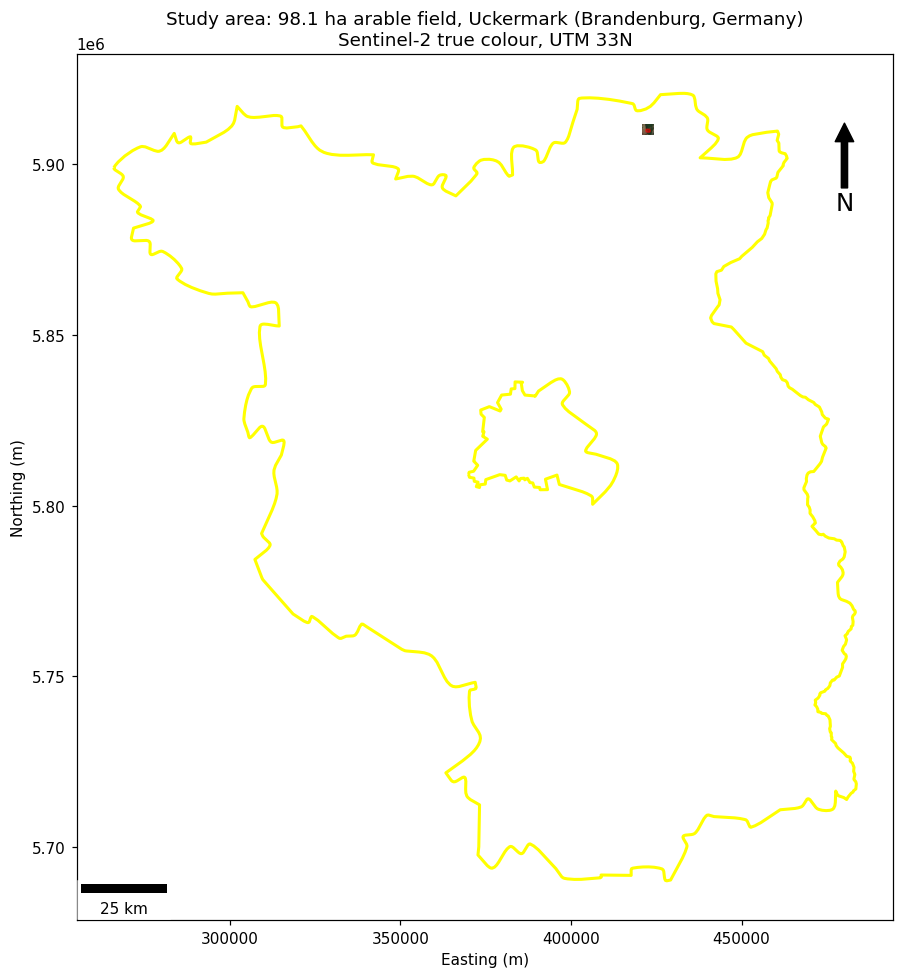

In [ ]:
if not USE_CACHED_RASTER:
    from matplotlib_scalebar.scalebar import ScaleBar

    field_ee = ee.Geometry(mapping(field_gdf.geometry.iloc[0]))

    # Attempt 1: Filter for 'Uckermark' by ADM2_NAME directly.
    # This is the desired specific context.
    context_fc_uckermark = (ee.FeatureCollection('FAO/GAUL/2015/level2')
                            .filter(ee.Filter.eq('ADM2_NAME', 'Uckermark')))

    # Attempt 2: If 'Uckermark' wasn't found by name, try to find any ADM2 feature
    # that intersects the field boundary. This provides a general administrative context.
    if context_fc_uckermark.size().getInfo() == 0:
        context_fc_general = (ee.FeatureCollection('FAO/GAUL/2015/level2')
                              .filterBounds(field_ee))
        if context_fc_general.size().getInfo() > 0:
            context_fc = context_fc_general
            # Get the name of the first feature for informative printing
            first_feature_name = context_fc.first().get('ADM2_NAME').getInfo()
            print(f"Warning: Specific 'Uckermark' (ADM2_NAME) not found. Using a general administrative unit "
                  f"('{first_feature_name}') intersecting the field for context.")
        else:
            # Last resort: if no ADM2 feature at all intersects the field, then context_fc remains empty.
            context_fc = ee.FeatureCollection([]) # Explicitly empty FC
            print("Error: No FAO/GAUL/2015/level2 administrative boundaries found intersecting the field.")
    else:
        context_fc = context_fc_uckermark
        print("Found 'Uckermark' administrative boundary for map context.")

    # Now, check if context_fc is still empty before proceeding with operations that require features.
    if context_fc.size().getInfo() == 0:
        print("Skipping generation of the study area map due to missing valid administrative context.")
    else:
        s2_rgb = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(context_fc).filterDate('2024-06-01', '2024-08-31')
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)).median()
                  .visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000))

        bg_path = f'{OUT_DIR}/background_utm.tif'
        if not os.path.exists(bg_path):
            # The region might be too large, leading to 'Pixel grid dimensions' error.
            # Limiting the export region to a buffer around the field to avoid exceeding EE's size limits.
            geemap.ee_export_image(s2_rgb, filename=bg_path, scale=20,
                                   region=field_ee.buffer(1000).bounds(), # Changed region here
                                   crs=UTM_CRS, file_per_band=False)

        context_gdf = geemap.ee_to_gdf(context_fc)
        if context_gdf.crs is None:
            context_gdf = context_gdf.set_crs('EPSG:4326')
        context_gdf = context_gdf.to_crs(UTM_CRS)

        fig, ax = plt.subplots(figsize=(9, 9))
        with rasterio.open(bg_path) as src:
            ax.imshow(np.transpose(src.read()[:3], (1, 2, 0)),
                      extent=rasterio.plot.plotting_extent(src))
        context_gdf.boundary.plot(ax=ax, color='yellow', linewidth=2)
        field_utm.plot(ax=ax, facecolor='red', edgecolor='red', alpha=0.5)
        ax.annotate('N', xy=(0.94, 0.92), xytext=(0.94, 0.82), ha='center', fontsize=16,
                    xycoords='axes fraction',
                    arrowprops=dict(facecolor='black', width=4, headwidth=12))
        ax.add_artist(ScaleBar(1, location='lower left', box_alpha=0.7))
        ax.set_title(f'Study area: {FIELD_AREA_HA:.1f} ha arable field, Uckermark '
                     '(Brandenburg, Germany)\nSentinel-2 true colour, UTM 33N')
        ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
        plt.tight_layout()
        plt.savefig(f'{OUT_DIR}/Fig1_study_area.png', dpi=200, bbox_inches='tight')
        plt.show()
else:
    print('Skipped (running from cached raster).')

## §2. Reference NDVI surface, correctly clipped *(reviewer comment 3)*

**The bug.** The earlier notebook used `geemap.ee_to_numpy(..., region=field)`,
which returns the array over the **bounding box** of the region. With a 98.1 ha
parcel that produced a 379.4 ha array, so pixels from neighbouring parcels,
tracks and field margins entered the "ground truth", the sampling frame and the
K-means zoning.

**The fix**, in two independent layers:

1. The Earth Engine image is `.clip()`-ed to the parcel and exported as a
   **georeferenced GeoTIFF in UTM 33N** (not a bare array), so the true affine
   transform survives.
2. `rasterio.mask.mask(..., crop=True)` then masks and crops that GeoTIFF to the
   exact polygon. Pixels outside the parcel become `NaN` and are excluded
   everywhere downstream.

The **clip audit** below prints polygon area, bounding-box area and clipped
valid-pixel area side by side, and raises an `AssertionError` if the clipped
raster does not match the polygon to within `AREA_TOLERANCE`. The bug cannot
silently reappear.

In [ ]:
SENTINEL = -9999.0

if not USE_CACHED_RASTER:
    def mask_s2_clouds(img):
        qa = img.select('QA60')
        m = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
        return img.updateMask(m).divide(10000).copyProperties(
            img, ['system:time_start', 'system:index'])

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(field_ee).filterDate(DATE_START, DATE_END)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', MAX_CLOUD_PCT))
          .map(mask_s2_clouds)
          .map(lambda i: i.addBands(i.normalizedDifference(['B8', 'B4']).rename('NDVI'))))

    N_SCENES = int(s2.size().getInfo())
    print(f'{N_SCENES} Sentinel-2 scenes in the composite window')
    assert N_SCENES > 0, 'No scenes -- widen DATE_START/DATE_END or raise MAX_CLOUD_PCT.'

    ndvi_image = s2.select('NDVI').median().clip(field_ee)

    # Export georeferenced, in UTM, clipped. unmask() so cloud gaps are explicit
    # rather than silently becoming 0.0 (a *valid* NDVI value).
    geemap.ee_export_image(ndvi_image.unmask(SENTINEL), filename=NDVI_TIF_RAW,
                           scale=PIXEL_SIZE, region=field_ee.bounds(),
                           crs=UTM_CRS, file_per_band=False)
    print(f'Reference raster exported -> {NDVI_TIF_RAW}')
else:
    N_SCENES = None
    print('Using cached reference raster.')

7 Sentinel-2 scenes in the composite window
Generating URL ...
Please wait ...
Data downloaded to /content/output/ndvi_reference_utm_raw.tif
Reference raster exported -> output/ndvi_reference_utm_raw.tif


In [ ]:
# ---------------------------------------------------------------------------
# Hard clip to the parcel polygon + CLIP AUDIT  (reviewer comment 3)
# ---------------------------------------------------------------------------
with rasterio.open(NDVI_TIF_RAW) as src:
    raw_h, raw_w = src.height, src.width
    raw_area_ha  = raw_h * raw_w * PIXEL_SIZE ** 2 / 1e4
    geoms = [mapping(field_utm.geometry.iloc[0])]
    clipped, clip_transform = rio_mask(src, geoms, crop=True, filled=True, nodata=SENTINEL)
    src_crs = src.crs

ndvi = clipped[0].astype(float)
ndvi[ndvi <= -1] = np.nan          # sentinel, nodata and impossible NDVI -> NaN
ndvi[ndvi > 1]   = np.nan

n_rows, n_cols = ndvi.shape
n_valid        = int(np.sum(~np.isnan(ndvi)))
clip_bbox_ha   = n_rows * n_cols * PIXEL_SIZE ** 2 / 1e4
valid_area_ha  = n_valid * PIXEL_SIZE ** 2 / 1e4
rel_err        = abs(valid_area_ha - FIELD_AREA_HA) / FIELD_AREA_HA

print('=' * 66)
print('CLIP AUDIT')
print('=' * 66)
print(f'  Parcel polygon area                : {FIELD_AREA_HA:8.2f} ha')
print(f'  Exported raster (bounding box)     : {raw_area_ha:8.2f} ha   '
      f'[{raw_h} x {raw_w} px]')
print(f'  After crop to polygon bbox         : {clip_bbox_ha:8.2f} ha   '
      f'[{n_rows} x {n_cols} px]')
print(f'  Valid pixels inside polygon        : {valid_area_ha:8.2f} ha   '
      f'[{n_valid:,} px]')
print(f'  Polygon vs valid-pixel discrepancy : {100*rel_err:8.2f} %')
print('=' * 66)

assert rel_err < AREA_TOLERANCE, (
    f'CLIPPING BUG: valid-pixel area {valid_area_ha:.1f} ha does not match the '
    f'{FIELD_AREA_HA:.1f} ha polygon (>{100*AREA_TOLERANCE:.0f}% off). '
    'Check that the image was .clip()-ed and that the mask geometry is in the raster CRS.')
print('PASS -- the analysed pixels are the parcel, not its bounding box.')

if raw_area_ha > 0:
    print(f'\nFor the manuscript: bounding-box extraction would have included '
          f'{raw_area_ha - valid_area_ha:.1f} ha ({100*(raw_area_ha/valid_area_ha - 1):.0f}%) '
          'of pixels outside the parcel.')

# Persist the clipped reference raster -- this is the ground truth for everything below
with rasterio.open(NDVI_TIF_CLIP, 'w', driver='GTiff', height=n_rows, width=n_cols,
                   count=1, dtype='float32', crs=src_crs, transform=clip_transform,
                   nodata=SENTINEL) as dst:
    dst.write(np.where(np.isnan(ndvi), SENTINEL, ndvi).astype('float32'), 1)
print(f'Clipped reference raster saved -> {NDVI_TIF_CLIP}')

CLIP AUDIT
  Parcel polygon area                :    98.10 ha
  Exported raster (bounding box)     :   131.52 ha   [96 x 137 px]
  After crop to polygon bbox         :   126.90 ha   [94 x 135 px]
  Valid pixels inside polygon        :    98.11 ha   [9,811 px]
  Polygon vs valid-pixel discrepancy :     0.01 %
PASS -- the analysed pixels are the parcel, not its bounding box.

For the manuscript: bounding-box extraction would have included 33.4 ha (34%) of pixels outside the parcel.
Clipped reference raster saved -> output/ndvi_reference_utm_clipped.tif


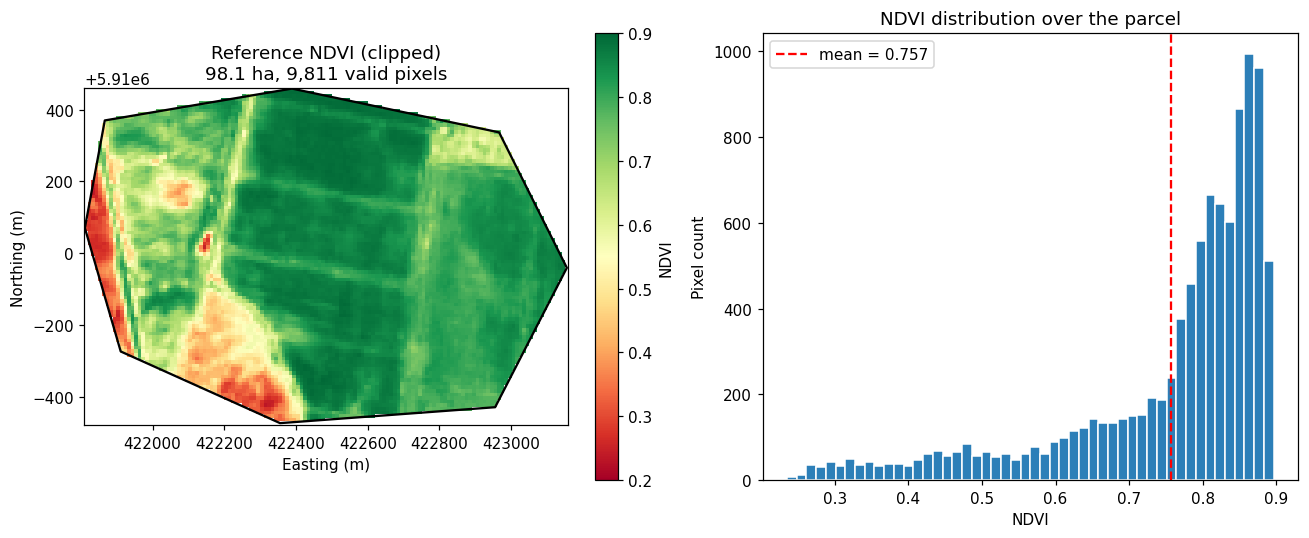

{'mean': 0.7573, 'std': 0.1435, 'vmin': 0.2351, 'vmax': 0.8962}


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
extent = rasterio.transform.array_bounds(n_rows, n_cols, clip_transform)
plot_extent = [extent[0], extent[2], extent[1], extent[3]]

im = axes[0].imshow(ndvi, cmap='RdYlGn', vmin=0.2, vmax=0.9, extent=plot_extent)
field_utm.boundary.plot(ax=axes[0], color='black', linewidth=1.5)
axes[0].set_title(f'Reference NDVI (clipped)\n{valid_area_ha:.1f} ha, {n_valid:,} valid pixels')
axes[0].set_xlabel('Easting (m)'); axes[0].set_ylabel('Northing (m)')
plt.colorbar(im, ax=axes[0], fraction=0.046, label='NDVI')

vals = ndvi[~np.isnan(ndvi)]
axes[1].hist(vals, bins=50, color='#2c7fb8', edgecolor='white')
axes[1].axvline(vals.mean(), color='red', ls='--', label=f'mean = {vals.mean():.3f}')
axes[1].set_title('NDVI distribution over the parcel')
axes[1].set_xlabel('NDVI'); axes[1].set_ylabel('Pixel count'); axes[1].legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig2_reference_ndvi.png', dpi=200, bbox_inches='tight')
plt.show()

NDVI_STATS = dict(mean=float(vals.mean()), std=float(vals.std()),
                  vmin=float(vals.min()), vmax=float(vals.max()))
print({k: round(v, 4) for k, v in NDVI_STATS.items()})

## §3. Sampling frame and interpolation methods

Coordinates are handled in **local metres** with the origin at the clipped
raster's upper-left corner (`x = col × 10 m`, `y = row × 10 m`). This is an exact
rigid shift of UTM 33N — Euclidean distances are true metres — and it keeps the
kriging solver numerically well conditioned. §9 converts back to UTM/WGS84 for
the exported products.

`draw_samples(seed, n)` is the one function that generates a sparse realisation:
it draws `n` pixel locations from the valid (in-parcel) pixels only and adds
Gaussian sensor noise. Every experiment below calls it with a different seed,
which is what makes the repeated-run statistics meaningful.

In [ ]:
rowi, coli = np.meshgrid(np.arange(n_rows), np.arange(n_cols), indexing='ij')
x_all = (coli * PIXEL_SIZE).astype(float).ravel()
y_all = (rowi * PIXEL_SIZE).astype(float).ravel()
z_all = ndvi.ravel()

valid_flat = ~np.isnan(z_all)
x_full, y_full, z_full = x_all[valid_flat], y_all[valid_flat], z_all[valid_flat]
grid_x_1d = np.arange(n_cols) * PIXEL_SIZE
grid_y_1d = np.arange(n_rows) * PIXEL_SIZE
print(f'{len(x_full):,} valid pixels available as the sampling frame')


def draw_samples(seed, n, noise_std=NOISE_STD):
    """One sparse-sampling realisation: n in-parcel locations + Gaussian sensor noise."""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(x_full), size=n, replace=False)
    xs, ys, z_true = x_full[idx], y_full[idx], z_full[idx]
    z_meas = z_true + rng.normal(0.0, noise_std, size=n)
    return xs, ys, z_true, z_meas


def metrics(true, pred):
    ok = ~np.isnan(pred) & ~np.isnan(true)
    return dict(RMSE=float(np.sqrt(mean_squared_error(true[ok], pred[ok]))),
                MAE=float(mean_absolute_error(true[ok], pred[ok])),
                R2=float(r2_score(true[ok], pred[ok])))

9,811 valid pixels available as the sampling frame


In [ ]:
# --------------------------- IDW ---------------------------
def idw_interpolate(xk, yk, zk, xq, yq, power=2, k=8):
    """Inverse distance weighting via a KD-tree nearest-neighbour lookup."""
    tree = cKDTree(np.column_stack([xk, yk]))
    k = min(k, len(xk))
    d, i = tree.query(np.column_stack([xq, yq]), k=k)
    if k == 1:
        d, i = d[:, None], i[:, None]
    d = np.where(d == 0, 1e-6, d)          # query point exactly on a sample
    w = 1.0 / d ** power
    w /= w.sum(axis=1, keepdims=True)
    return np.sum(w * zk[i], axis=1)


def idw_loocv_rmse(x, y, z, power, k):
    preds = np.empty_like(z)
    for i in range(len(z)):
        m = np.ones(len(z), bool); m[i] = False
        preds[i] = idw_interpolate(x[m], y[m], z[m], x[i:i+1], y[i:i+1], power, k)[0]
    return float(np.sqrt(mean_squared_error(z, preds)))


IDW_GRID = [(p, k) for p in IDW_POWERS for k in IDW_NEIGHBOURS]

def tune_idw(x, y, z, return_table=False):
    """LOOCV tuning of (power, k) on TRAINING points only -- no test-set leakage."""
    scores = {pk: idw_loocv_rmse(x, y, z, *pk) for pk in IDW_GRID}
    (power, k), best = min(scores.items(), key=lambda kv: kv[1])
    if return_table:
        tab = (pd.DataFrame([(p, kk, v) for (p, kk), v in scores.items()],
                            columns=['power', 'k', 'LOOCV RMSE'])
               .sort_values('LOOCV RMSE').reset_index(drop=True))
        return power, k, best, tab
    return power, k, best


# ------------------------- Kriging -------------------------
def fit_kriging(x, y, z, model):
    return OrdinaryKriging(x, y, z, variogram_model=model,
                           verbose=False, enable_plotting=False)


def krige_points(ok, xq, yq):
    pred, var = ok.execute('points', xq, yq)
    return np.ma.filled(pred, np.nan), np.ma.filled(var, np.nan)


def krige_grid(ok, gx=None, gy=None):
    gx = grid_x_1d if gx is None else gx
    gy = grid_y_1d if gy is None else gy
    pred, var = ok.execute('grid', gx, gy)
    surf = np.ma.filled(pred, np.nan)
    std  = np.sqrt(np.ma.filled(var, np.nan))
    surf[np.isnan(ndvi)] = np.nan          # keep everything inside the parcel
    std[np.isnan(ndvi)]  = np.nan
    return surf, std


def krige_loocv_rmse(x, y, z, model):
    preds = np.empty_like(z)
    for i in range(len(z)):
        m = np.ones(len(z), bool); m[i] = False
        ok = fit_kriging(x[m], y[m], z[m], model)
        preds[i] = krige_points(ok, x[i:i+1], y[i:i+1])[0][0]
    return float(np.sqrt(mean_squared_error(z, preds)))


def variogram_fit_sse(ok):
    """Sum of squared residuals between experimental and fitted semivariance."""
    fitted = ok.variogram_function(ok.variogram_model_parameters, ok.lags)
    return float(np.sum((ok.semivariance - fitted) ** 2))

print('Interpolators ready.')

Interpolators ready.


## §4. Variogram model selection *(reviewer comment 5)*

The previous version used the spherical model because it is the common default,
with no evidence it was the right choice. Here four candidate models —
**spherical, exponential, gaussian, linear** — are compared on two criteria,
across `VARIOGRAM_SEL_REPEATS` independent sample realisations so the choice is
not an artefact of one lucky draw:

- **Kriging LOOCV RMSE** — predictive skill, the criterion that actually matters
  for reconstruction;
- **Variogram fit SSE** — how well the fitted model tracks the experimental
  semivariogram, the conventional geostatistical goodness-of-fit.

The model with the lowest mean LOOCV RMSE is selected and used for every kriging
run in the rest of the notebook.

In [ ]:
rows = []
for r in range(VARIOGRAM_SEL_REPEATS):
    seed = MASTER_SEED + 100 * r
    xs, ys, z_true, z_meas = draw_samples(seed, N_SAMPLES_MAIN)
    for model in VARIOGRAM_CANDIDATES:
        try:
            ok = fit_kriging(xs, ys, z_meas, model)
            rows.append(dict(seed=seed, model=model,
                             loocv_rmse=krige_loocv_rmse(xs, ys, z_meas, model),
                             fit_sse=variogram_fit_sse(ok)))
        except Exception as e:
            rows.append(dict(seed=seed, model=model, loocv_rmse=np.nan, fit_sse=np.nan))
            print(f'  {model} failed on seed {seed}: {type(e).__name__}')

vario_runs = pd.DataFrame(rows)
vario_summary = (vario_runs.groupby('model')
                 .agg(LOOCV_RMSE_mean=('loocv_rmse', 'mean'),
                      LOOCV_RMSE_sd=('loocv_rmse', 'std'),
                      FitSSE_mean=('fit_sse', 'mean'),
                      n_ok=('loocv_rmse', 'count'))
                 .sort_values('LOOCV_RMSE_mean'))

VARIOGRAM_MODEL = vario_summary.index[0]
print(f'Variogram model comparison over {VARIOGRAM_SEL_REPEATS} sample realisations '
      f'(n = {N_SAMPLES_MAIN}):\n')
print(vario_summary.round(5).to_string())
print(f'\nSELECTED MODEL: {VARIOGRAM_MODEL} (lowest mean kriging LOOCV RMSE)')

vario_summary.to_csv(f'{OUT_DIR}/T1_variogram_model_comparison.csv')

Variogram model comparison over 10 sample realisations (n = 50):

             LOOCV_RMSE_mean  LOOCV_RMSE_sd  FitSSE_mean  n_ok
model                                                         
exponential          0.10392        0.01171      0.00059    10
spherical            0.10632        0.01259      0.00043    10
linear               0.11113        0.01292      0.00024    10
gaussian             0.74942        1.98787      0.00034    10

SELECTED MODEL: exponential (lowest mean kriging LOOCV RMSE)


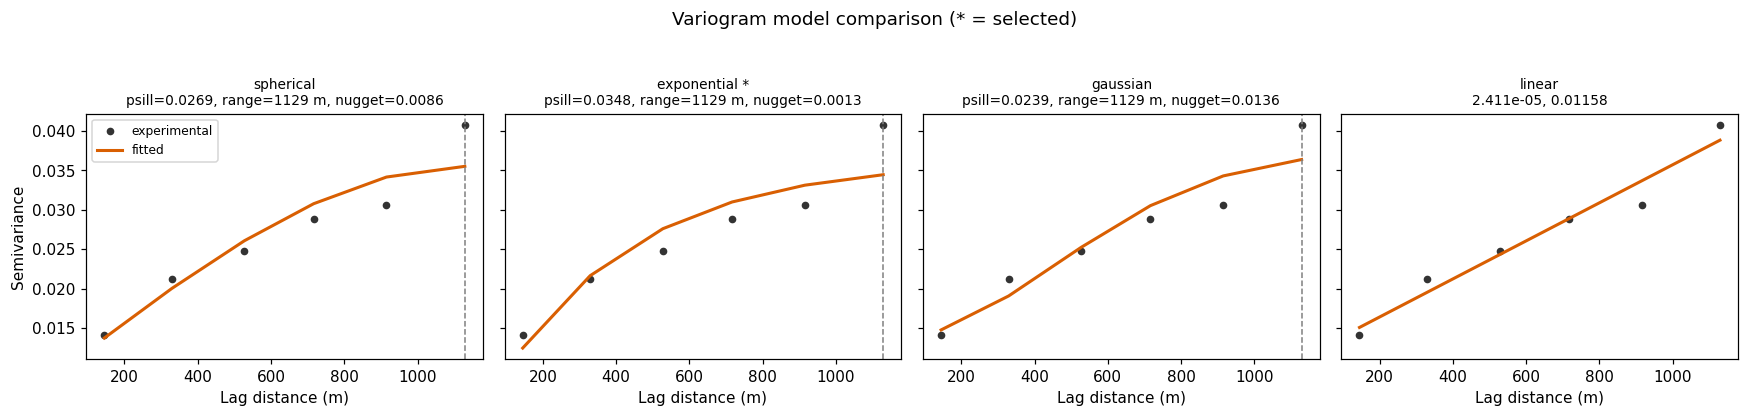

Selected exponential variogram -- partial sill 0.03483, range 1129 m, nugget 0.00133
Interpretation: samples more than ~1129 m apart are effectively uncorrelated, so that is the upper bound on a useful sampling grid spacing on this field (~127.4 ha per sample at that spacing).


In [ ]:
# Experimental vs fitted semivariogram for every candidate, on one realisation
xs, ys, z_true, z_meas = draw_samples(MASTER_SEED, N_SAMPLES_MAIN)

fig, axes = plt.subplots(1, len(VARIOGRAM_CANDIDATES),
                         figsize=(4 * len(VARIOGRAM_CANDIDATES), 3.6), sharey=True)
axes = np.atleast_1d(axes)
vario_params = {}

for ax, model in zip(axes, VARIOGRAM_CANDIDATES):
    try:
        ok = fit_kriging(xs, ys, z_meas, model)
        fitted = ok.variogram_function(ok.variogram_model_parameters, ok.lags)
        ax.plot(ok.lags, ok.semivariance, 'o', ms=4, color='#333', label='experimental')
        ax.plot(ok.lags, fitted, '-', lw=2, color='#d95f02', label='fitted')
        params = ok.variogram_model_parameters
        vario_params[model] = params
        if model in ('spherical', 'exponential', 'gaussian'):
            psill, rng_, nug = params
            ax.axvline(rng_, color='gray', ls='--', lw=1)
            sub = f'psill={psill:.4f}, range={rng_:.0f} m, nugget={nug:.4f}'
        else:
            sub = ', '.join(f'{p:.4g}' for p in params)
        ttl = model + (' *' if model == VARIOGRAM_MODEL else '')
        ax.set_title(f'{ttl}\n{sub}', fontsize=9)
        ax.set_xlabel('Lag distance (m)')
    except Exception as e:
        ax.set_title(f'{model}: failed'); ax.axis('off')

axes[0].set_ylabel('Semivariance'); axes[0].legend(fontsize=8)
plt.suptitle('Variogram model comparison (* = selected)', y=1.04)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig3_variogram_models.png', dpi=200, bbox_inches='tight')
plt.show()

if VARIOGRAM_MODEL in ('spherical', 'exponential', 'gaussian'):
    PSILL, VARIO_RANGE, NUGGET = vario_params[VARIOGRAM_MODEL]
    print(f'Selected {VARIOGRAM_MODEL} variogram -- partial sill {PSILL:.5f}, '
          f'range {VARIO_RANGE:.0f} m, nugget {NUGGET:.5f}')
    print(f'Interpretation: samples more than ~{VARIO_RANGE:.0f} m apart are effectively '
          'uncorrelated, so that is the upper bound on a useful sampling grid spacing '
          f'on this field (~{(VARIO_RANGE**2)/1e4:.1f} ha per sample at that spacing).')
else:
    PSILL = VARIO_RANGE = NUGGET = np.nan

## §4b. Machine-learning and deep-learning predictors

The submitted abstract compared only two geostatistical interpolators — in a
session on **AI in Remote Sensing**. This section adds five learning-based
predictors so the benchmark actually covers the session's topic, and so the
claim "kriging is the right tool here" is tested against modern alternatives
rather than assumed.

**Why plain (x, y) regression fails, and what we do instead.** A tree ensemble
given only coordinates produces axis-aligned, blocky surfaces — it has no notion
of distance decay. The standard remedy in spatial ML (cf. Hengl et al. 2018,
*Random forest as a generic framework for spatial prediction*) is to hand the
learner explicit **spatial features**. Each prediction location is described by:

- its coordinates `x, y`;
- the distances `d₁…d_K` to its *K* nearest training samples;
- the values `z₁…z_K` of those samples;
- an inverse-distance estimate and the local mean of those *K* neighbours.

This makes the learner a *trainable local interpolator* rather than a coordinate
lookup table. **Leakage control:** when these features are built for the training
points themselves, each point's own value is excluded from its neighbour set
(`exclude_self=True`), otherwise `z₁` would be the answer and every tree would
memorise it.

**The methods:**

| Method | Family | What it contributes |
|---|---|---|
| IDW (LOOCV-tuned) | deterministic | baseline |
| Ordinary Kriging | geostatistical | baseline, gives uncertainty |
| Random Forest | ensemble ML | non-linear, handles feature interactions |
| Gradient Boosting | ensemble ML | usually the stronger tabular learner |
| Gaussian Process (Matérn) | probabilistic ML | the ML formulation of kriging — kernel hyperparameters are learned by marginal-likelihood optimisation instead of fitted from an experimental variogram, and it also returns a predictive SD |
| Fourier-feature MLP | neural network | coordinate-based implicit neural representation: random Fourier positional encoding → MLP, the standard fix for the spectral bias that makes plain MLPs blur spatial detail |
| RF + residual kriging | hybrid | regression kriging — ML learns the trend, kriging models the spatially correlated residual |

**Expect the neural network to lose, and report that honestly.** With `n` = 50
samples, of which 40 are used for training, deep learning is being asked to fit a
2-D field from forty numbers. That is far below the data regime where neural
networks beat geostatistics, and a negative result here is a *useful* result for
an AI-in-remote-sensing audience — it marks where the data threshold lies. Do not
tune the MLP against the test set to rescue it.

Every method is wrapped in the same interface — `fit(x, y, z) → predict(xq, yq)`
returning `(prediction, standard_deviation_or_None)` — so §5, §6 and §7 loop over
them generically and every method is evaluated under identical conditions.

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

K_NEIGHBOURS = 8                       # neighbours used for the spatial feature block
FIELD_EXTENT = float(max(x_full.max(), y_full.max()))


def spatial_features(xq, yq, xt, yt, zt, K=K_NEIGHBOURS, exclude_self=False):
    """[x, y, d_1..d_K, z_1..z_K, idw_estimate, local_mean].

    exclude_self=True MUST be used when building features for the training points
    themselves, otherwise each point's own value leaks in as its nearest neighbour.
    """
    tree = cKDTree(np.column_stack([xt, yt]))
    kq = min(K + (1 if exclude_self else 0), len(xt))
    d, i = tree.query(np.column_stack([xq, yq]), k=kq)
    if kq == 1:
        d, i = d[:, None], i[:, None]
    if exclude_self:
        d, i = d[:, 1:], i[:, 1:]
    zk = zt[i]
    dd = np.where(d == 0, 1e-6, d)
    w = 1.0 / dd ** 2
    w /= w.sum(axis=1, keepdims=True)
    return np.column_stack([xq, yq, d, zk, np.sum(w * zk, axis=1), zk.mean(axis=1)])


def fourier_features(xq, yq, B):
    """Random Fourier positional encoding: counters the spectral bias of plain MLPs."""
    P = np.column_stack([xq, yq]) @ B.T
    return np.column_stack([np.sin(P), np.cos(P)])

print(f'Spatial feature block: {2 + 2*K_NEIGHBOURS + 2} features per location')

Spatial feature block: 20 features per location


In [ ]:
# --------------------------------------------------------------------------
# Method registry. Each factory: fit(x, y, z) -> (predict_fn, info_dict)
# where predict_fn(xq, yq) -> (prediction, sd or None)
# --------------------------------------------------------------------------
def fit_idw(x, y, z):
    power, k, loocv = tune_idw(x, y, z)
    return (lambda xq, yq: (idw_interpolate(x, y, z, xq, yq, power, k), None)), \
           dict(power=power, k=k, loocv=loocv)


def fit_kriging_method(x, y, z):
    ok = fit_kriging(x, y, z, VARIOGRAM_MODEL)
    def predict(xq, yq):
        pred, var = ok.execute('points', xq, yq)
        return np.ma.filled(pred, np.nan), np.sqrt(np.clip(np.ma.filled(var, np.nan), 0, None))
    return predict, dict(model=VARIOGRAM_MODEL)


def _tree_factory(make_estimator):
    def fit(x, y, z):
        est = make_estimator()
        est.fit(spatial_features(x, y, x, y, z, exclude_self=True), z)   # leakage-safe
        return (lambda xq, yq: (est.predict(spatial_features(xq, yq, x, y, z)), None)), {}
    return fit


fit_rf = _tree_factory(lambda: RandomForestRegressor(
    n_estimators=300, min_samples_leaf=1, random_state=MASTER_SEED, n_jobs=-1))
fit_gbm = _tree_factory(lambda: HistGradientBoostingRegressor(
    max_iter=300, learning_rate=0.08, min_samples_leaf=3, random_state=MASTER_SEED))


def fit_gpr(x, y, z):
    """Gaussian process regression -- kernel hyperparameters learned by marginal likelihood."""
    sc = StandardScaler().fit(np.column_stack([x, y]))
    kern = (ConstantKernel(1.0, (1e-3, 1e3))
            * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e2), nu=1.5)
            + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e0)))
    gp = GaussianProcessRegressor(kernel=kern, normalize_y=True, n_restarts_optimizer=2,
                                  random_state=MASTER_SEED)
    gp.fit(sc.transform(np.column_stack([x, y])), z)
    def predict(xq, yq):
        m, s = gp.predict(sc.transform(np.column_stack([xq, yq])), return_std=True)
        return m, s
    return predict, dict(kernel=str(gp.kernel_))


def fit_ffmlp(x, y, z, n_freq=48):
    """Coordinate MLP with random Fourier features (implicit neural representation).

    The encoding bandwidth sigma is chosen by K-fold CV on the TRAINING points only.
    """
    best, best_cv = None, np.inf
    for sigma in (0.5, 1.5, 4.0):
        rng = np.random.default_rng(MASTER_SEED)
        B = rng.normal(0, sigma, (n_freq, 2)) / FIELD_EXTENT * 2 * np.pi
        F = fourier_features(x, y, B)
        errs = []
        for tr_i, te_i in KFold(n_splits=min(5, len(z)), shuffle=True,
                                random_state=MASTER_SEED).split(F):
            m = MLPRegressor(hidden_layer_sizes=(64, 64), activation='relu', solver='adam',
                             alpha=1e-3, learning_rate_init=5e-3, max_iter=1500,
                             random_state=MASTER_SEED)
            m.fit(F[tr_i], z[tr_i])
            errs.append(mean_squared_error(z[te_i], m.predict(F[te_i])))
        if np.mean(errs) < best_cv:
            best_cv, best = np.mean(errs), (sigma, B)
    sigma, B = best
    mdl = MLPRegressor(hidden_layer_sizes=(64, 64), activation='relu', solver='adam',
                       alpha=1e-3, learning_rate_init=5e-3, max_iter=3000,
                       random_state=MASTER_SEED)
    mdl.fit(fourier_features(x, y, B), z)
    return (lambda xq, yq: (mdl.predict(fourier_features(xq, yq, B)), None)), \
           dict(sigma=sigma, cv_mse=float(best_cv))


def fit_rf_rk(x, y, z):
    """Regression kriging: RF trend + ordinary kriging of the RF residuals."""
    base, _ = fit_rf(x, y, z)
    resid = z - base(x, y)[0]
    if float(np.std(resid)) < 1e-9:
        return (lambda xq, yq: (base(xq, yq)[0], None)), dict(note='zero residual variance')
    ok = fit_kriging(x, y, resid, VARIOGRAM_MODEL)
    def predict(xq, yq):
        r, _ = ok.execute('points', xq, yq)
        return base(xq, yq)[0] + np.ma.filled(r, 0.0), None
    return predict, {}


METHODS = {
    'IDW (LOOCV-tuned)':          fit_idw,
    'Ordinary Kriging':           fit_kriging_method,
    'Random Forest':              fit_rf,
    'Gradient Boosting':          fit_gbm,
    'Gaussian Process (Matérn)':  fit_gpr,
    'Fourier-feature MLP':        fit_ffmlp,
    'RF + residual kriging':      fit_rf_rk,
}
METHOD_NAMES = list(METHODS)
METHOD_FAMILY = {'IDW (LOOCV-tuned)': 'deterministic', 'Ordinary Kriging': 'geostatistical',
                 'Random Forest': 'machine learning', 'Gradient Boosting': 'machine learning',
                 'Gaussian Process (Matérn)': 'machine learning',
                 'Fourier-feature MLP': 'deep learning', 'RF + residual kriging': 'hybrid'}
METHOD_COLORS = dict(zip(METHOD_NAMES, ['#1b9e77', '#762a83', '#d95f02', '#e7298a',
                                        '#7570b3', '#66a61e', '#a6761d']))
print(f'{len(METHODS)} methods registered:')
for n in METHOD_NAMES:
    print(f'  - {n:28s} [{METHOD_FAMILY[n]}]')

7 methods registered:
  - IDW (LOOCV-tuned)            [deterministic]
  - Ordinary Kriging             [geostatistical]
  - Random Forest                [machine learning]
  - Gradient Boosting            [machine learning]
  - Gaussian Process (Matérn)    [machine learning]
  - Fourier-feature MLP          [deep learning]
  - RF + residual kriging        [hybrid]


In [ ]:
# Smoke test: fit every method once on the reference realisation and time it
_xs, _ys, _zt, _zm = draw_samples(MASTER_SEED, N_SAMPLES_MAIN)
_tr, _te = train_test_split(np.arange(N_SAMPLES_MAIN), test_size=TEST_FRACTION,
                            random_state=MASTER_SEED)
import time
_rows = []
for _name, _f in METHODS.items():
    _t0 = time.time()
    _pred, _info = _f(_xs[_tr], _ys[_tr], _zm[_tr])
    _p = _pred(_xs[_te], _ys[_te])[0]
    _rows.append(dict(Method=_name, Family=METHOD_FAMILY[_name],
                      **metrics(_zt[_te], _p), fit_s=round(time.time() - _t0, 2)))
smoke = pd.DataFrame(_rows).sort_values('RMSE')
print('Smoke test (single split -- indicative only, see section 5 for the real comparison):\n')
print(smoke.round(4).to_string(index=False))
print(f'\nEstimated section 5 runtime: '
      f'~{smoke.fit_s.sum() * 2 * N_REPEATS / 60:.1f} min for {N_REPEATS} repetitions.')

Smoke test (single split -- indicative only, see section 5 for the real comparison):

                   Method           Family   RMSE    MAE     R2  fit_s
      Fourier-feature MLP    deep learning 0.0487 0.0418 0.8867   0.55
    RF + residual kriging           hybrid 0.0514 0.0411 0.8742   0.70
        IDW (LOOCV-tuned)    deterministic 0.0544 0.0439 0.8587   0.18
            Random Forest machine learning 0.0577 0.0475 0.8413   1.15
         Ordinary Kriging   geostatistical 0.0591 0.0468 0.8334   0.02
Gaussian Process (Matérn) machine learning 0.0690 0.0577 0.7728   0.20
        Gradient Boosting machine learning 0.0787 0.0583 0.7047   0.39

Estimated section 5 runtime: ~5.3 min for 50 repetitions.


## §5. Repeated-split validation across all methods *(reviewer comment 1)*

This is the comment that mattered most. The submitted abstract rested on **one**
random split of **10** held-out points at `seed=42`, and across notebook versions
R² moved between 0.90 and 0.33–0.53 while the "better" method flipped. That is
sampling noise being read as a result.

Each of the `N_REPEATS` repetitions:

1. draws a **fresh** sparse realisation (`RESAMPLE_POINTS = True`, so sample
   locations *and* the split vary — the two sources of variance the single-split
   design confounded);
2. splits 80 / 20 into training and held-out points;
3. fits **every method in the registry on exactly the same training points**, with
   all hyperparameter selection (IDW's power/k, the MLP's Fourier bandwidth, the
   GP's kernel) done **inside** the run on training data only;
4. scores each method on the held-out points **and** on every valid pixel in the
   parcel — a full-field score over ~10⁴ pixels rather than 10 points.

Because all methods see identical data in every run, the runs are **paired** and
support repeated-measures testing.

In [ ]:
import time

records = []
t_start = time.time()

for r in range(N_REPEATS):
    seed = MASTER_SEED + r
    sample_seed = seed if RESAMPLE_POINTS else MASTER_SEED
    xs, ys, z_true, z_meas = draw_samples(sample_seed, N_SAMPLES_MAIN)
    tr, te = train_test_split(np.arange(N_SAMPLES_MAIN),
                              test_size=TEST_FRACTION, random_state=seed)

    for name, factory in METHODS.items():
        # --- held-out validation: trained on the training points only ---
        predict, info = factory(xs[tr], ys[tr], z_meas[tr])
        p_te, sd_te = predict(xs[te], ys[te])
        rec = dict(run=r, seed=seed, method=name, family=METHOD_FAMILY[name],
                   **{f'ho_{k}': v for k, v in metrics(z_true[te], p_te).items()})

        # uncertainty calibration, where the method provides an SD
        if sd_te is not None:
            zstd = (z_true[te] - p_te) / np.sqrt(np.clip(sd_te, 1e-9, None) ** 2)
            rec['rmsse'] = float(np.sqrt(np.nanmean(zstd ** 2)))
            rec['std_bias'] = float(np.nanmean(zstd))
        else:
            rec['rmsse'] = np.nan
            rec['std_bias'] = np.nan

        # --- full-field: refit on all samples, score every valid pixel ---
        if FULL_FIELD_EACH_RUN:
            predict_all, _ = factory(xs, ys, z_meas)
            p_ff = predict_all(x_full, y_full)[0]
            rec.update({f'ff_{k}': v for k, v in metrics(z_full, p_ff).items()})

        records.append(rec)

    if (r + 1) % 10 == 0:
        el = time.time() - t_start
        print(f'  {r + 1}/{N_REPEATS} repetitions ({el/60:.1f} min elapsed, '
              f'~{el/(r+1)*(N_REPEATS-r-1)/60:.1f} min left)')

runs = pd.DataFrame(records)
runs.to_csv(f'{OUT_DIR}/T2_repeated_split_runs.csv', index=False)
print(f'\n{N_REPEATS} repetitions x {len(METHODS)} methods = {len(runs)} fits '
      f'in {(time.time()-t_start)/60:.1f} min')

/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  10/50 repetitions (1.2 min elapsed, ~4.9 min left)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning:

  20/50 repetitions (2.4 min elapsed, ~3.6 min left)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning:

  30/50 repetitions (3.5 min elapsed, ~2.3 min left)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  40/50 repetitions (4.6 min elapsed, ~1.2 min left)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  50/50 repetitions (5.8 min elapsed, ~0.0 min left)

50 repetitions x 7 methods = 350 fits in 5.8 min


In [ ]:
def method_summary(prefix, label):
    out = []
    for name in METHOD_NAMES:
        g = runs[runs.method == name]
        row = {'Method': name, 'Family': METHOD_FAMILY[name]}
        for m in ('RMSE', 'MAE', 'R2'):
            v = g[f'{prefix}{m}']
            row[m] = f'{v.mean():.4f} ± {v.std(ddof=1):.4f}'
        row['_sort'] = g[f'{prefix}RMSE'].mean()
        out.append(row)
    df = pd.DataFrame(out).sort_values('_sort').drop(columns='_sort').reset_index(drop=True)
    df.insert(0, 'Rank', range(1, len(df) + 1))
    print(f'\n{label}\n' + '-' * len(label))
    print(df.to_string(index=False))
    return df

held_out = method_summary('ho_', f'HELD-OUT POINTS -- mean ± SD over {N_REPEATS} repetitions '
                                 f'(n = {int(N_SAMPLES_MAIN*TEST_FRACTION)} points per run)')
held_out.to_csv(f'{OUT_DIR}/T3_heldout_repeated.csv', index=False)

if FULL_FIELD_EACH_RUN:
    full_field = method_summary('ff_', f'FULL FIELD -- mean ± SD over {N_REPEATS} repetitions '
                                       f'({len(z_full):,} pixels per run)')
    full_field.to_csv(f'{OUT_DIR}/T4_fullfield_repeated.csv', index=False)

BEST_HO = held_out.iloc[0].Method
BEST_FF = full_field.iloc[0].Method if FULL_FIELD_EACH_RUN else BEST_HO
print(f'\nLowest mean RMSE -- held-out: {BEST_HO} | full-field: {BEST_FF}')

# Instability of the single-split design, quantified for the manuscript
print(f'\nWhy the single split was unsafe -- held-out R² range across the '
      f'{N_REPEATS} repetitions:')
for name in METHOD_NAMES:
    g = runs[runs.method == name]
    print(f'  {name:28s} {g.ho_R2.min():6.2f} to {g.ho_R2.max():5.2f}  '
          f'(SD {g.ho_R2.std(ddof=1):.2f})')
idw_v_kr = (runs[runs.method == "Ordinary Kriging"].ho_RMSE.values <
            runs[runs.method == "IDW (LOOCV-tuned)"].ho_RMSE.values)
print(f'\nKriging beat IDW on held-out RMSE in {100*idw_v_kr.mean():.0f}% of runs '
      '-- a single run could have shown either method "winning".')


HELD-OUT POINTS -- mean ± SD over 50 repetitions (n = 10 points per run)
------------------------------------------------------------------------
 Rank                    Method           Family            RMSE             MAE               R2
    1          Ordinary Kriging   geostatistical 0.0891 ± 0.0352 0.0635 ± 0.0212  0.3177 ± 0.4401
    2         IDW (LOOCV-tuned)    deterministic 0.0905 ± 0.0347 0.0629 ± 0.0218  0.2810 ± 0.5072
    3     RF + residual kriging           hybrid 0.0958 ± 0.0379 0.0668 ± 0.0243  0.1462 ± 0.6952
    4 Gaussian Process (Matérn) machine learning 0.0968 ± 0.0411 0.0691 ± 0.0258  0.2031 ± 0.5666
    5             Random Forest machine learning 0.0976 ± 0.0372 0.0695 ± 0.0245  0.0997 ± 0.8451
    6       Fourier-feature MLP    deep learning 0.1030 ± 0.0429 0.0752 ± 0.0313 -0.0390 ± 1.0685
    7         Gradient Boosting machine learning 0.1098 ± 0.0463 0.0778 ± 0.0321 -0.2186 ± 1.5977

FULL FIELD -- mean ± SD over 50 repetitions (9,811 pixels per run)
-

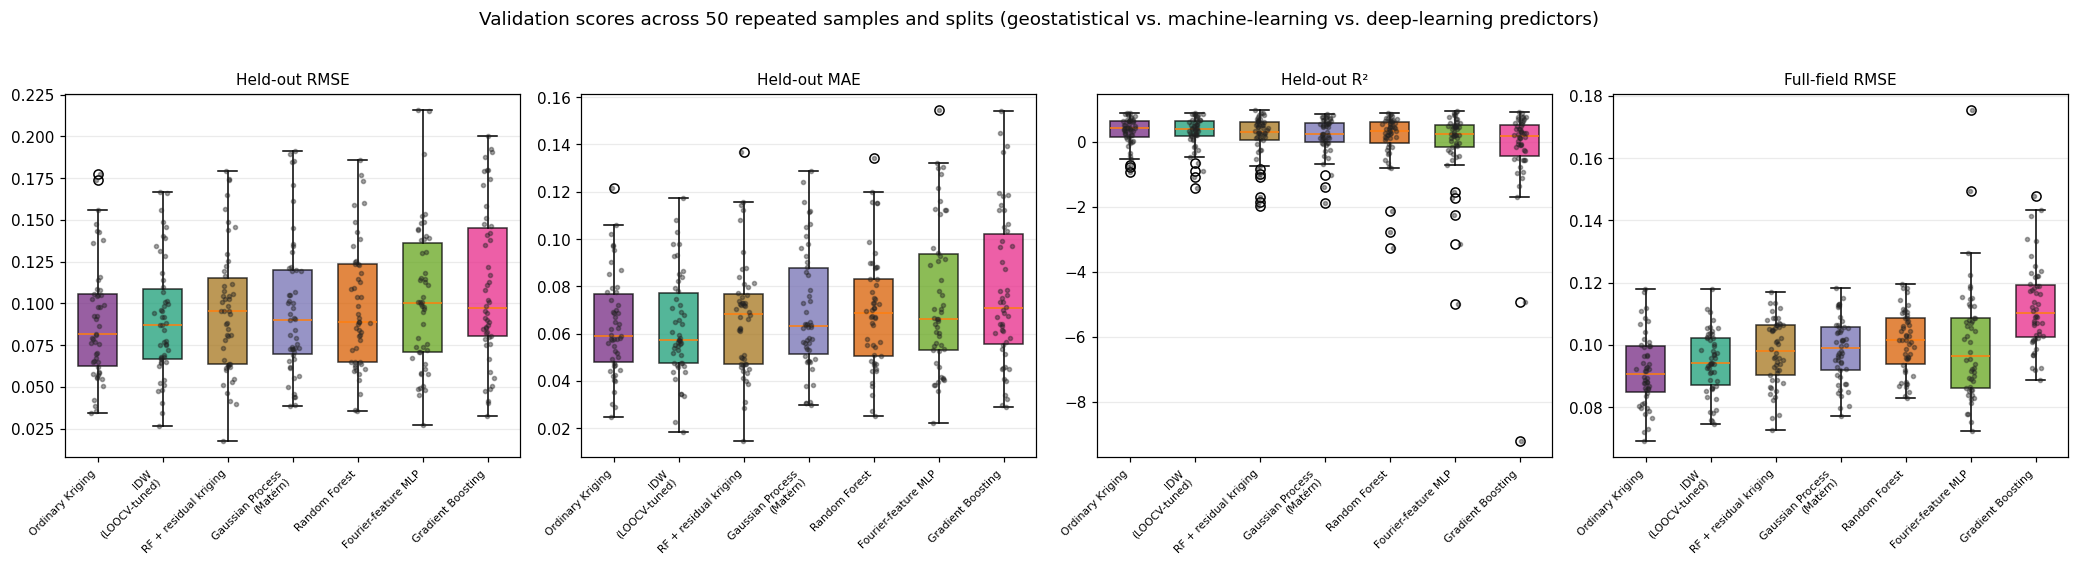

In [ ]:
fig, axes = plt.subplots(1, 3 if not FULL_FIELD_EACH_RUN else 4, figsize=(19, 5))
panels = [('ho_RMSE', 'Held-out RMSE'), ('ho_MAE', 'Held-out MAE'), ('ho_R2', 'Held-out R²')]
if FULL_FIELD_EACH_RUN:
    panels.append(('ff_RMSE', 'Full-field RMSE'))

order = held_out.Method.tolist()
for ax, (col, title) in zip(np.atleast_1d(axes), panels):
    data = [runs[runs.method == m][col].values for m in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    for patch, m in zip(bp['boxes'], order):
        patch.set_facecolor(METHOD_COLORS[m]); patch.set_alpha(0.75)
    for i, m in enumerate(order, start=1):
        v = runs[runs.method == m][col].values
        ax.scatter(np.random.normal(i, 0.05, len(v)), v, s=7, color='#222', alpha=0.4, zorder=3)
    ax.set_xticklabels([m.replace(' (', '\n(') for m in order], rotation=45,
                       ha='right', fontsize=7)
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.25, axis='y')

plt.suptitle(f'Validation scores across {N_REPEATS} repeated samples and splits '
             '(geostatistical vs. machine-learning vs. deep-learning predictors)', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig4_method_distributions.png', dpi=200, bbox_inches='tight')
plt.show()

### §5b. Significance testing across seven methods

With more than two methods, running every pairwise *t*-test would inflate the
false-positive rate. The standard protocol for comparing multiple predictors over
the same repeated runs (Demšar 2006) is used instead:

1. **Friedman test** — a non-parametric repeated-measures test asking whether *any*
   method differs. If it fails to reject, no pairwise claim is licensed at all.
2. **Post-hoc Wilcoxon signed-rank tests** of every method against the
   best-ranked one, with **Holm** correction across those comparisons.
3. **Mean rank** per method, which is what the Friedman test actually operates on
   and the most honest one-number summary.

The original IDW-vs-kriging pair — the specific claim in the submitted abstract —
is also reported separately with a paired *t*-test, CI and Cohen's *d*.

In [ ]:
def holm(pvals):
    """Holm-Bonferroni step-down adjusted p-values."""
    p = np.asarray(pvals, float)
    order = np.argsort(p); m = len(p); adj = np.empty(m); prev = 0.0
    for rank, idx in enumerate(order):
        prev = max(prev, min((m - rank) * p[idx], 1.0))
        adj[idx] = prev
    return adj


ALPHA = 0.05
metric_col, metric_label = 'ho_RMSE', 'held-out RMSE'

wide = runs.pivot(index='run', columns='method', values=metric_col)[METHOD_NAMES]
ranks = wide.rank(axis=1)                      # 1 = best (lowest RMSE) in each run
mean_ranks = ranks.mean().sort_values()

chi2, p_friedman = sstats.friedmanchisquare(*[wide[m].values for m in METHOD_NAMES])
print(f'FRIEDMAN TEST on {metric_label} across {len(METHOD_NAMES)} methods, '
      f'{N_REPEATS} runs')
print(f'  chi² = {chi2:.2f}, df = {len(METHOD_NAMES)-1}, p = {p_friedman:.2e}')
print('  ->', 'at least one method differs; post-hoc tests are licensed.'
      if p_friedman < ALPHA else
      'NO significant difference between any methods -- do not claim a winner.')

print('\nMean rank (1 = best):')
for m, v in mean_ranks.items():
    print(f'  {v:5.2f}  {m}')

control = mean_ranks.index[0]
post = []
if p_friedman < ALPHA:
    for m in METHOD_NAMES:
        if m == control:
            continue
        try:
            _, pw = sstats.wilcoxon(wide[control], wide[m])
        except ValueError:
            pw = np.nan
        d = wide[m] - wide[control]
        post.append(dict(Comparison=f'{control} vs {m}',
                         **{'Δ mean RMSE': f'{d.mean():+.4f}',
                            'Control wins': f'{100*(wide[control] < wide[m]).mean():.0f}%',
                            'p (Wilcoxon)': pw}))
    post_df = pd.DataFrame(post)
    post_df['p (Holm-adj.)'] = holm(post_df['p (Wilcoxon)'].values)
    post_df['Significant'] = np.where(post_df['p (Holm-adj.)'] < ALPHA, 'yes', 'no')
    for c in ('p (Wilcoxon)', 'p (Holm-adj.)'):
        post_df[c] = post_df[c].map(lambda v: f'{v:.4f}' if pd.notna(v) else 'n/a')
    print(f'\nPOST-HOC: every method vs. the best-ranked ({control}), Holm-corrected\n')
    print(post_df.to_string(index=False))
    post_df.to_csv(f'{OUT_DIR}/T5_posthoc_tests.csv', index=False)
    n_sig = int((post_df.Significant == 'yes').sum())
    print(f'\n{control} is significantly better than {n_sig} of '
          f'{len(post_df)} other methods after correction.')
else:
    post_df = pd.DataFrame()

FRIEDMAN TEST on held-out RMSE across 7 methods, 50 runs
  chi² = 35.55, df = 6, p = 3.38e-06
  -> at least one method differs; post-hoc tests are licensed.

Mean rank (1 = best):
   3.00  IDW (LOOCV-tuned)
   3.04  Ordinary Kriging
   3.90  RF + residual kriging
   4.16  Gaussian Process (Matérn)
   4.32  Random Forest
   4.72  Fourier-feature MLP
   4.86  Gradient Boosting

POST-HOC: every method vs. the best-ranked (IDW (LOOCV-tuned)), Holm-corrected

                                    Comparison Δ mean RMSE Control wins p (Wilcoxon) p (Holm-adj.) Significant
         IDW (LOOCV-tuned) vs Ordinary Kriging     -0.0014          50%       0.7741        0.7741          no
            IDW (LOOCV-tuned) vs Random Forest     +0.0071          70%       0.0028        0.0112         yes
        IDW (LOOCV-tuned) vs Gradient Boosting     +0.0192          76%       0.0000        0.0002         yes
IDW (LOOCV-tuned) vs Gaussian Process (Matérn)     +0.0063          68%       0.0083        0.020

In [ ]:
# The specific pairwise claim made in the submitted abstract: IDW vs Ordinary Kriging
a = wide['IDW (LOOCV-tuned)'].values
b = wide['Ordinary Kriging'].values
d = a - b
t_stat, p_t = sstats.ttest_rel(a, b)
try:
    _, p_w = sstats.wilcoxon(a, b)
except ValueError:
    p_w = np.nan
lo, hi = sstats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=sstats.sem(d))
cohen_d = d.mean() / d.std(ddof=1)

pair = pd.DataFrame([dict(Comparison='IDW vs Ordinary Kriging',
                          **{'IDW mean': f'{a.mean():.4f}', 'Kriging mean': f'{b.mean():.4f}',
                             'Mean diff': f'{d.mean():+.4f}', '95% CI': f'[{lo:+.4f}, {hi:+.4f}]',
                             'p (paired t)': f'{p_t:.4f}', 'p (Wilcoxon)': f'{p_w:.4f}',
                             "Cohen's d": f'{cohen_d:+.3f}'})])
print('THE CLAIM MADE IN THE SUBMITTED ABSTRACT, RE-TESTED\n')
print(pair.to_string(index=False))
pair.to_csv(f'{OUT_DIR}/T5b_idw_vs_kriging.csv', index=False)

better = 'Ordinary Kriging' if d.mean() > 0 else 'IDW'
if p_t < ALPHA:
    PAIR_VERDICT = (f'{better} has the lower held-out RMSE and the difference is significant '
                    f'(paired t = {t_stat:.2f}, p = {p_t:.4f}, Cohen\'s d = {abs(cohen_d):.2f}).')
else:
    PAIR_VERDICT = (f'IDW and ordinary kriging are statistically indistinguishable on held-out '
                    f'RMSE (paired t-test p = {p_t:.3f}); the mean difference of {d.mean():+.4f} '
                    'NDVI units sits within run-to-run noise. The RMSE 0.066 vs 0.078 gap '
                    'reported in the submitted abstract was a single-split artefact.')

if p_friedman < ALPHA:
    OVERALL_VERDICT = (f'{control} ranked best overall (mean rank {mean_ranks.iloc[0]:.2f}; '
                       f'Friedman p = {p_friedman:.1e}). {PAIR_VERDICT}')
else:
    OVERALL_VERDICT = ('No method differed significantly from any other (Friedman p = '
                       f'{p_friedman:.3f}). ' + PAIR_VERDICT)
print('\n' + '=' * 78)
print('VERDICT:', OVERALL_VERDICT)
print('=' * 78)

THE CLAIM MADE IN THE SUBMITTED ABSTRACT, RE-TESTED

             Comparison IDW mean Kriging mean Mean diff             95% CI p (paired t) p (Wilcoxon) Cohen's d
IDW vs Ordinary Kriging   0.0905       0.0891   +0.0014 [-0.0018, +0.0045]       0.3794       0.7741    +0.125

VERDICT: IDW (LOOCV-tuned) ranked best overall (mean rank 3.00; Friedman p = 3.4e-06). IDW and ordinary kriging are statistically indistinguishable on held-out RMSE (paired t-test p = 0.379); the mean difference of +0.0014 NDVI units sits within run-to-run noise. The RMSE 0.066 vs 0.078 gap reported in the submitted abstract was a single-split artefact.


### §5c. Does the AI add anything?

The question a reviewer in an AI session will ask directly. Grouping the methods
by family answers it in one table: if the learning-based predictors do not beat
ordinary kriging at this sample size, that is the finding, and it belongs in the
paper as such — the informative result is *where the crossover is*, not a
manufactured win.

In [ ]:
fam = (runs.groupby(['family', 'method'])
       .agg(ho_RMSE=('ho_RMSE', 'mean'), ho_R2=('ho_R2', 'mean'),
            ff_RMSE=('ff_RMSE', 'mean') if FULL_FIELD_EACH_RUN else ('ho_RMSE', 'mean'))
       .reset_index().sort_values('ho_RMSE'))
print('METHOD FAMILIES RANKED\n')
print(fam.round(4).to_string(index=False))
fam.to_csv(f'{OUT_DIR}/T5c_family_comparison.csv', index=False)

geo_best = runs[runs.family.isin(['deterministic', 'geostatistical'])].groupby('method').ho_RMSE.mean().min()
ml_best  = runs[runs.family == 'machine learning'].groupby('method').ho_RMSE.mean().min()
dl_best  = runs[runs.family == 'deep learning'].groupby('method').ho_RMSE.mean().min()
hy_best  = runs[runs.family == 'hybrid'].groupby('method').ho_RMSE.mean().min()

print(f'\nBest held-out RMSE by family:')
print(f'  geostatistical / deterministic : {geo_best:.4f}')
print(f'  machine learning               : {ml_best:.4f}  ({100*(ml_best/geo_best-1):+.1f}% vs geo)')
print(f'  deep learning                  : {dl_best:.4f}  ({100*(dl_best/geo_best-1):+.1f}% vs geo)')
print(f'  hybrid                         : {hy_best:.4f}  ({100*(hy_best/geo_best-1):+.1f}% vs geo)')

if dl_best > geo_best:
    AI_VERDICT = (f'At n = {N_SAMPLES_MAIN} the neural predictor is {100*(dl_best/geo_best-1):.0f}% '
                  'worse than the best geostatistical method: forty training points are far below '
                  'the regime where a coordinate network can learn a spatial field. This is a '
                  'data-regime limit, not a failure of the architecture -- see the density sweep '
                  'in section 6 for how the gap narrows as samples increase.')
else:
    AI_VERDICT = (f'The neural predictor matched or beat the geostatistical baseline at '
                  f'n = {N_SAMPLES_MAIN} ({100*(dl_best/geo_best-1):+.0f}%), which is unusual at '
                  'this sample size and worth verifying on a second field before publishing.')
print('\n' + AI_VERDICT)

METHOD FAMILIES RANKED

          family                    method  ho_RMSE   ho_R2  ff_RMSE
  geostatistical          Ordinary Kriging   0.0891  0.3177   0.0917
   deterministic         IDW (LOOCV-tuned)   0.0905  0.2810   0.0944
          hybrid     RF + residual kriging   0.0958  0.1462   0.0977
machine learning Gaussian Process (Matérn)   0.0968  0.2031   0.0984
machine learning             Random Forest   0.0976  0.0997   0.1011
   deep learning       Fourier-feature MLP   0.1030 -0.0390   0.1003
machine learning         Gradient Boosting   0.1098 -0.2186   0.1122

Best held-out RMSE by family:
  geostatistical / deterministic : 0.0891
  machine learning               : 0.0968  (+8.6% vs geo)
  deep learning                  : 0.1030  (+15.5% vs geo)
  hybrid                         : 0.0958  (+7.5% vs geo)

At n = 50 the neural predictor is 16% worse than the best geostatistical method: forty training points are far below the regime where a coordinate network can learn a spatial 

UNCERTAINTY CALIBRATION (RMSSE = 1 means the predictive SD matches the observed error)

                           RMSSE_mean  RMSSE_sd  std_bias
method                                                   
Gaussian Process (Matérn)       1.115     0.473     0.010
Ordinary Kriging                0.881     0.339     0.017


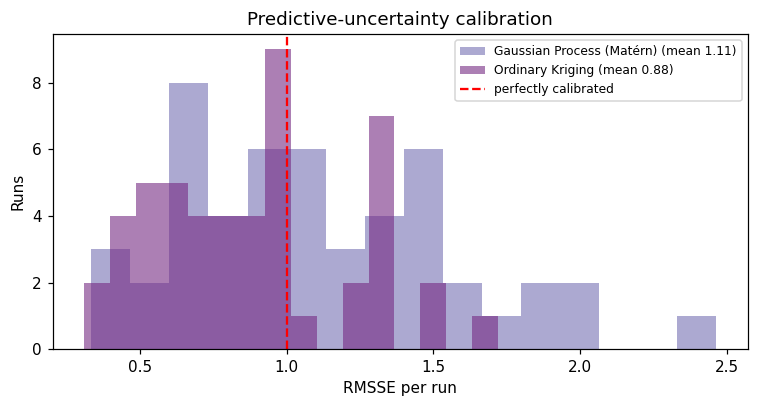

RMSSE close to 1: the kriging predictive variance is well calibrated against observed held-out errors, supporting its use as a per-pixel uncertainty layer.


In [ ]:
# Uncertainty calibration: kriging and the Gaussian process both return a predictive SD.
unc = runs[runs.rmsse.notna()]
if len(unc):
    cal = (unc.groupby('method')
           .agg(RMSSE_mean=('rmsse', 'mean'), RMSSE_sd=('rmsse', 'std'),
                std_bias=('std_bias', 'mean')))
    print('UNCERTAINTY CALIBRATION (RMSSE = 1 means the predictive SD matches the '
          'observed error)\n')
    print(cal.round(3).to_string())
    cal.to_csv(f'{OUT_DIR}/T5d_uncertainty_calibration.csv')

    fig, ax = plt.subplots(figsize=(7, 3.8))
    for m in cal.index:
        ax.hist(unc[unc.method == m].rmsse, bins=16, alpha=0.6,
                label=f'{m} (mean {cal.loc[m, "RMSSE_mean"]:.2f})',
                color=METHOD_COLORS.get(m, '#888'))
    ax.axvline(1.0, color='red', ls='--', label='perfectly calibrated')
    ax.set_xlabel('RMSSE per run'); ax.set_ylabel('Runs')
    ax.set_title('Predictive-uncertainty calibration'); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/Fig5_uncertainty_calibration.png', dpi=200, bbox_inches='tight')
    plt.show()

    rmsse_mean = float(cal.loc['Ordinary Kriging', 'RMSSE_mean'])
    if rmsse_mean < 0.8:
        CALIB = ('RMSSE < 1: the kriging variance is conservative -- it over-states prediction '
                 'uncertainty, so the map ranks locations correctly for adaptive sampling but '
                 'its absolute values are not exact confidence bounds.')
    elif rmsse_mean > 1.25:
        CALIB = ('RMSSE > 1: the kriging variance under-states the true error, so the '
                 'uncertainty map is optimistic in absolute terms.')
    else:
        CALIB = ('RMSSE close to 1: the kriging predictive variance is well calibrated against '
                 'observed held-out errors, supporting its use as a per-pixel uncertainty layer.')
    print(CALIB)
else:
    rmsse_mean, CALIB = np.nan, 'No method returned a predictive standard deviation.'
    print(CALIB)

## §6. Sampling density: where does each method break down? *(reviewer comment 4)*

The abstract's pitch is that sparse sampling can be enough — but only *n* = 50 was
ever tested, so the claim had no support. Rerunning the whole comparison at
`DENSITIES` = 20 / 50 / 100 / 200 answers the reviewer and, with the learners
included, produces the more interesting result: **the sample size at which
learning-based methods catch up with geostatistics.** That crossover is the
genuinely novel contribution for an AI-in-remote-sensing audience.

In [ ]:
sweep_rows = []
t0 = time.time()
for di, n in enumerate(DENSITIES):
    for r in range(DENSITY_REPEATS):
        seed = MASTER_SEED + 1000 * (di + 1) + r
        xs, ys, z_true, z_meas = draw_samples(seed, n)
        tr, te = train_test_split(np.arange(n), test_size=TEST_FRACTION, random_state=seed)
        for name, factory in METHODS.items():
            predict, _ = factory(xs[tr], ys[tr], z_meas[tr])
            m_ho = metrics(z_true[te], predict(xs[te], ys[te])[0])
            predict_all, _ = factory(xs, ys, z_meas)
            m_ff = metrics(z_full, predict_all(x_full, y_full)[0])
            sweep_rows.append(dict(n=n, rep=r, method=name, family=METHOD_FAMILY[name],
                                   density=n / valid_area_ha,
                                   ho_RMSE=m_ho['RMSE'], ho_R2=m_ho['R2'],
                                   ff_RMSE=m_ff['RMSE'], ff_R2=m_ff['R2']))
    print(f'  n = {n:3d} done ({n/valid_area_ha:.2f} samples/ha, '
          f'{(time.time()-t0)/60:.1f} min elapsed)')

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(f'{OUT_DIR}/T6_density_sweep_runs.csv', index=False)

density_summary = (sweep.groupby(['method', 'n'])
                   .agg(samples_per_ha=('density', 'mean'),
                        ho_RMSE_mean=('ho_RMSE', 'mean'), ho_RMSE_sd=('ho_RMSE', 'std'),
                        ff_RMSE_mean=('ff_RMSE', 'mean'), ff_RMSE_sd=('ff_RMSE', 'std'),
                        ff_R2_mean=('ff_R2', 'mean'))
                   .reset_index())
print(f'\nSAMPLING DENSITY SWEEP -- {DENSITY_REPEATS} repetitions per density per method\n')
print(density_summary.pivot(index='n', columns='method', values='ff_RMSE_mean')
      .round(4).to_string())
density_summary.to_csv(f'{OUT_DIR}/T7_density_summary.csv', index=False)

/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning:

  n =  20 done (0.20 samples/ha, 2.6 min elapsed)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning:

  n =  50 done (0.51 samples/ha, 6.1 min elapsed)


/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  n = 100 done (1.02 samples/ha, 10.6 min elapsed)
  n = 200 done (2.04 samples/ha, 17.8 min elapsed)

SAMPLING DENSITY SWEEP -- 30 repetitions per density per method

method  Fourier-feature MLP  Gaussian Process (Matérn)  Gradient Boosting  IDW (LOOCV-tuned)  Ordinary Kriging  RF + residual kriging  Random Forest
n                                                                                                                                                   
20                   0.1307                     0.1206             0.1367             0.1139            0.1124                 0.1176         0.1221
50                   0.0968                     0.0967             0.1140             0.0928            0.0898                 0.0982         0.1022
100                  0.0798                     0.0795             0.0950             0.0786            0.0724                 0.0804         0.0840
200                  0.0726                     0.0644             0.0746             0

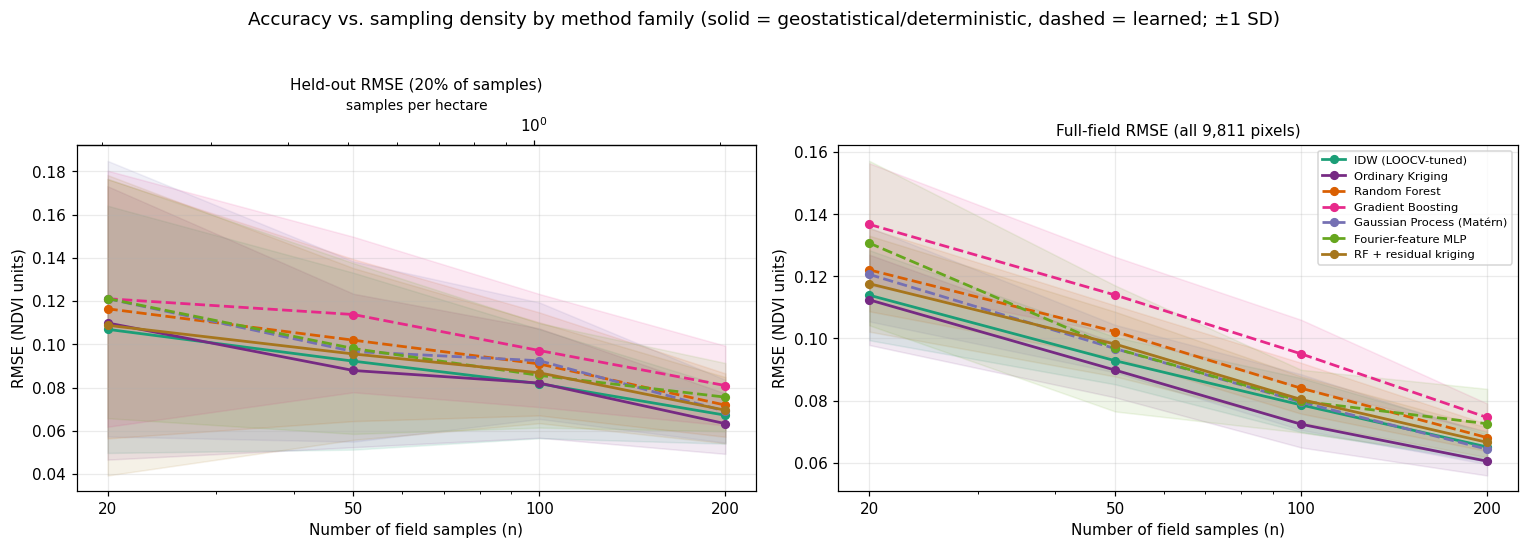


Best learned method vs. best geostatistical method (full-field RMSE):
  n =  20 (0.20/ha):   +7.3%   geostatistics wins
  n =  50 (0.51/ha):   +7.7%   geostatistics wins
  n = 100 (1.02/ha):   +9.8%   geostatistics wins
  n = 200 (2.04/ha):   +6.4%   geostatistics wins

CONCLUSION: no learned predictor overtakes geostatistics anywhere in the tested range (n = 20-200); the crossover, if it exists, lies above 200 samples (2.0/ha).


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (mcol, scol, title) in zip(axes, [
        ('ho_RMSE_mean', 'ho_RMSE_sd', f'Held-out RMSE ({int(100*TEST_FRACTION)}% of samples)'),
        ('ff_RMSE_mean', 'ff_RMSE_sd', f'Full-field RMSE (all {len(z_full):,} pixels)')]):
    for m in METHOD_NAMES:
        g = density_summary[density_summary.method == m].sort_values('n')
        ls = '--' if METHOD_FAMILY[m] in ('machine learning', 'deep learning') else '-'
        ax.plot(g.n, g[mcol], 'o' + ls, color=METHOD_COLORS[m], label=m, lw=1.8, ms=5)
        ax.fill_between(g.n, g[mcol] - g[scol], g[mcol] + g[scol],
                        color=METHOD_COLORS[m], alpha=0.10)
    ax.set_xscale('log'); ax.set_xticks(DENSITIES)
    ax.set_xticklabels(DENSITIES)
    ax.set_xlabel('Number of field samples (n)'); ax.set_ylabel('RMSE (NDVI units)')
    ax.set_title(title, fontsize=10); ax.grid(alpha=0.25)
axes[1].legend(fontsize=7.5, loc='upper right')
sec = axes[0].secondary_xaxis('top', functions=(lambda v: v / valid_area_ha,
                                                lambda v: v * valid_area_ha))
sec.set_xlabel('samples per hectare', fontsize=9)
plt.suptitle(f'Accuracy vs. sampling density by method family '
             '(solid = geostatistical/deterministic, dashed = learned; ±1 SD)', y=1.03)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/Fig6_density_sweep.png', dpi=200, bbox_inches='tight')
plt.show()

# Where, if anywhere, do the learners overtake the geostatistical baseline?
piv = density_summary.pivot(index='n', columns='method', values='ff_RMSE_mean')
geo_cols = [m for m in METHOD_NAMES if METHOD_FAMILY[m] in ('deterministic', 'geostatistical')]
learn_cols = [m for m in METHOD_NAMES if METHOD_FAMILY[m] in ('machine learning', 'deep learning')]
gap = (piv[learn_cols].min(axis=1) / piv[geo_cols].min(axis=1) - 1) * 100
print('\nBest learned method vs. best geostatistical method (full-field RMSE):')
for n in piv.index:
    tag = 'learned method wins' if gap[n] < 0 else 'geostatistics wins'
    print(f'  n = {n:3d} ({n/valid_area_ha:.2f}/ha): {gap[n]:+6.1f}%   {tag}')
crossover = [n for n in piv.index if gap[n] < 0]
CROSSOVER = (f'learned predictors overtake geostatistics from n = {min(crossover)} '
             f'({min(crossover)/valid_area_ha:.2f} samples/ha) upward'
             if crossover else
             f'no learned predictor overtakes geostatistics anywhere in the tested range '
             f'(n = {min(DENSITIES)}-{max(DENSITIES)}); the crossover, if it exists, lies above '
             f'{max(DENSITIES)} samples ({max(DENSITIES)/valid_area_ha:.1f}/ha)')
print(f'\nCONCLUSION: {CROSSOVER}.')

## §7. Reference reconstruction — all methods side by side

The statistics above are the evidence; this section produces the map products,
using the fixed reference configuration (`N_SAMPLES_MAIN` samples, `MASTER_SEED`,
all samples as input). Its metrics are reported as *one realisation* alongside the
distributions from §5 — never on their own.

The map panel is also where the tree-ensemble weakness becomes visible: watch for
blocky, axis-aligned patches in the Random Forest and Gradient Boosting surfaces
even with the spatial feature block, versus the smooth fields from kriging and the
Gaussian process.

In [ ]:
xs_ref, ys_ref, z_true_ref, z_meas_ref = draw_samples(MASTER_SEED, N_SAMPLES_MAIN)
surfaces, sd_surfaces, ref_rows = {}, {}, []

for name, factory in METHODS.items():
    predict, info = factory(xs_ref, ys_ref, z_meas_ref)
    pred, sd = predict(x_full, y_full)
    surf = np.full(ndvi.shape, np.nan); surf.ravel()[valid_flat] = pred
    surfaces[name] = surf
    if sd is not None:
        s = np.full(ndvi.shape, np.nan); s.ravel()[valid_flat] = sd
        sd_surfaces[name] = s
    ref_rows.append(dict(Method=name, Family=METHOD_FAMILY[name], **metrics(z_full, pred)))

power_ref, k_ref, loocv_ref, idw_table = tune_idw(xs_ref, ys_ref, z_meas_ref, return_table=True)

ref_full = pd.DataFrame(ref_rows).sort_values('RMSE').reset_index(drop=True)
print(f'Full-field accuracy of the reference reconstruction '
      f'({len(z_full):,} pixels, single realisation, n = {N_SAMPLES_MAIN}):\n')
print(ref_full.round(4).to_string(index=False))
ref_full.to_csv(f'{OUT_DIR}/T8_reference_fullfield.csv', index=False)
print(f'\nIDW hyperparameters chosen by LOOCV: power = {power_ref}, k = {k_ref} '
      f'(LOOCV RMSE {loocv_ref:.4f})')

# The surface carried into zoning and export: best mean full-field RMSE from section 5
BEST_METHOD = BEST_FF
surface_for_zoning = surfaces[BEST_METHOD]
zoning_method_name = BEST_METHOD
print(f'Surface used for zoning and export: {BEST_METHOD} '
      '(best mean full-field RMSE across repetitions, not a single-run pick).')

Full-field accuracy of the reference reconstruction (9,811 pixels, single realisation, n = 50):

                   Method           Family   RMSE    MAE     R2
         Ordinary Kriging   geostatistical 0.0692 0.0460 0.7677
    RF + residual kriging           hybrid 0.0726 0.0480 0.7439
        IDW (LOOCV-tuned)    deterministic 0.0744 0.0503 0.7311
Gaussian Process (Matérn) machine learning 0.0771 0.0513 0.7116
      Fourier-feature MLP    deep learning 0.0777 0.0524 0.7073
            Random Forest machine learning 0.0831 0.0580 0.6652
        Gradient Boosting machine learning 0.0925 0.0636 0.5844

IDW hyperparameters chosen by LOOCV: power = 1, k = 4 (LOOCV RMSE 0.1045)
Surface used for zoning and export: Ordinary Kriging (best mean full-field RMSE across repetitions, not a single-run pick).


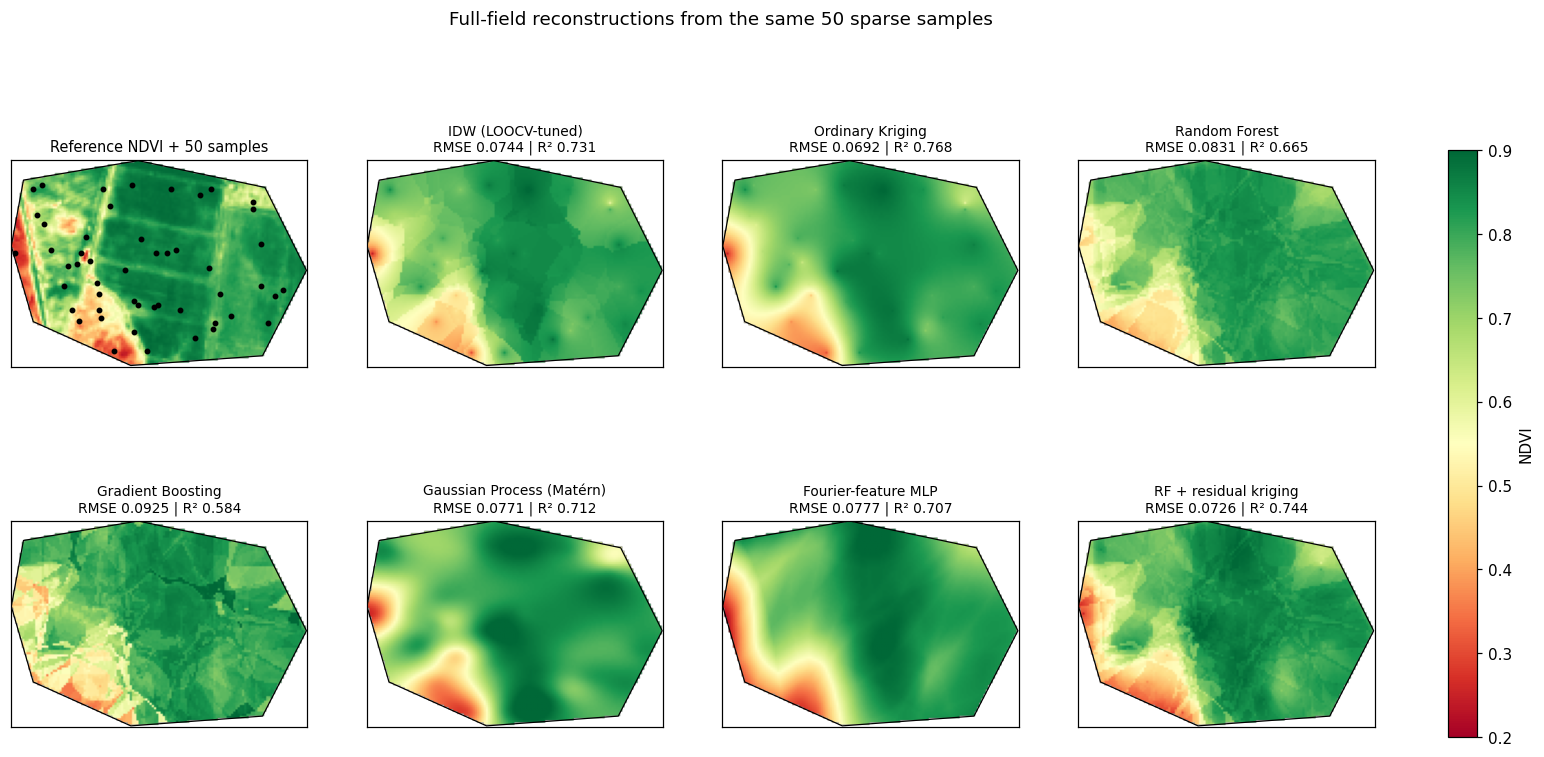

In [ ]:
n_panel = len(METHODS) + 1
ncol = 4
nrow = int(np.ceil(n_panel / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.3 * ncol, 3.9 * nrow))
axes = axes.ravel()
kw = dict(extent=plot_extent, origin='upper', cmap='RdYlGn', vmin=0.2, vmax=0.9)

im = axes[0].imshow(ndvi, **kw)
axes[0].scatter(clip_transform.c + xs_ref, clip_transform.f - ys_ref, c='black', s=8)
axes[0].set_title(f'Reference NDVI + {N_SAMPLES_MAIN} samples', fontsize=9.5)

for ax, name in zip(axes[1:], METHOD_NAMES):
    ax.imshow(surfaces[name], **kw)
    row = ref_full[ref_full.Method == name].iloc[0]
    ax.set_title(f'{name}\nRMSE {row.RMSE:.4f} | R² {row.R2:.3f}', fontsize=9)

for ax in axes[:n_panel]:
    field_utm.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes[n_panel:]:
    ax.axis('off')
fig.colorbar(im, ax=axes[:n_panel].tolist(), fraction=0.02, label='NDVI')
plt.suptitle('Full-field reconstructions from the same 50 sparse samples', y=1.0)
plt.savefig(f'{OUT_DIR}/Fig7_reconstructions.png', dpi=200, bbox_inches='tight')
plt.show()

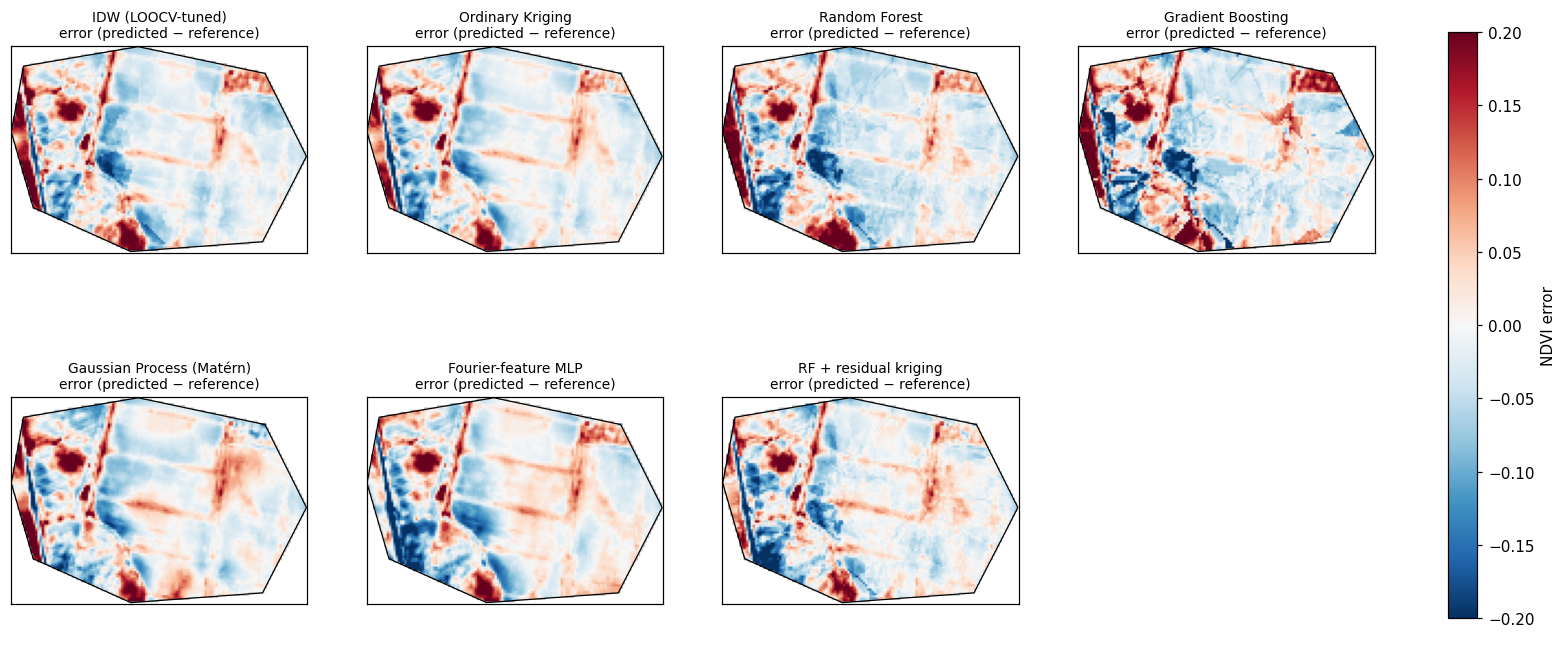

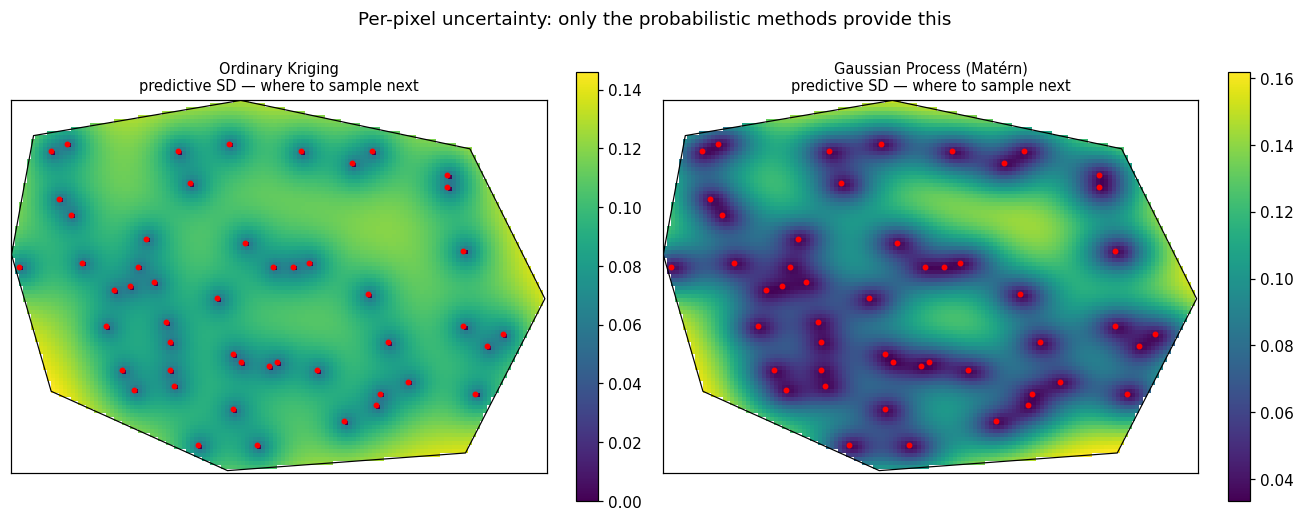

In [ ]:
# Error maps + the predictive-uncertainty surfaces (kriging and the GP provide these)
n_err = len(METHOD_NAMES)
fig, axes = plt.subplots(2, int(np.ceil(n_err / 2)), figsize=(4.3 * np.ceil(n_err/2), 7.6))
axes = axes.ravel()
for ax, name in zip(axes, METHOD_NAMES):
    im = ax.imshow(surfaces[name] - ndvi, cmap='RdBu_r', vmin=-0.2, vmax=0.2,
                   extent=plot_extent, origin='upper')
    ax.set_title(f'{name}\nerror (predicted − reference)', fontsize=9)
    field_utm.boundary.plot(ax=ax, color='black', linewidth=0.8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes[n_err:]:
    ax.axis('off')
fig.colorbar(im, ax=axes.tolist(), fraction=0.02, label='NDVI error')
plt.savefig(f'{OUT_DIR}/Fig7b_error_maps.png', dpi=200, bbox_inches='tight')
plt.show()

if sd_surfaces:
    fig, axes = plt.subplots(1, len(sd_surfaces), figsize=(6 * len(sd_surfaces), 4.6),
                             squeeze=False)
    for ax, (name, s) in zip(axes[0], sd_surfaces.items()):
        im = ax.imshow(s, cmap='viridis', extent=plot_extent, origin='upper')
        ax.scatter(clip_transform.c + xs_ref, clip_transform.f - ys_ref, c='red', s=8)
        field_utm.boundary.plot(ax=ax, color='black', linewidth=0.8)
        ax.set_title(f'{name}\npredictive SD — where to sample next', fontsize=9.5)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.suptitle('Per-pixel uncertainty: only the probabilistic methods provide this', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/Fig7c_uncertainty_surfaces.png', dpi=200, bbox_inches='tight')
    plt.show()

## §8. Management zones

Proof of concept for the variable-rate step: K-means on the reconstructed surface,
cluster labels re-ordered by mean NDVI so zone 0 is always the lowest-vigor class.
Agreement against zones derived from the reference raster quantifies how much
reconstruction error survives into the agronomic decision — the number that
actually matters for a variable-rate prescription.

Agreement with zones derived from the reference raster:

                   Method  Zone agreement (%)
Gaussian Process (Matérn)                82.0
            Random Forest                81.9
         Ordinary Kriging                81.4
    RF + residual kriging                79.6
      Fourier-feature MLP                78.3
        IDW (LOOCV-tuned)                72.3
        Gradient Boosting                71.6


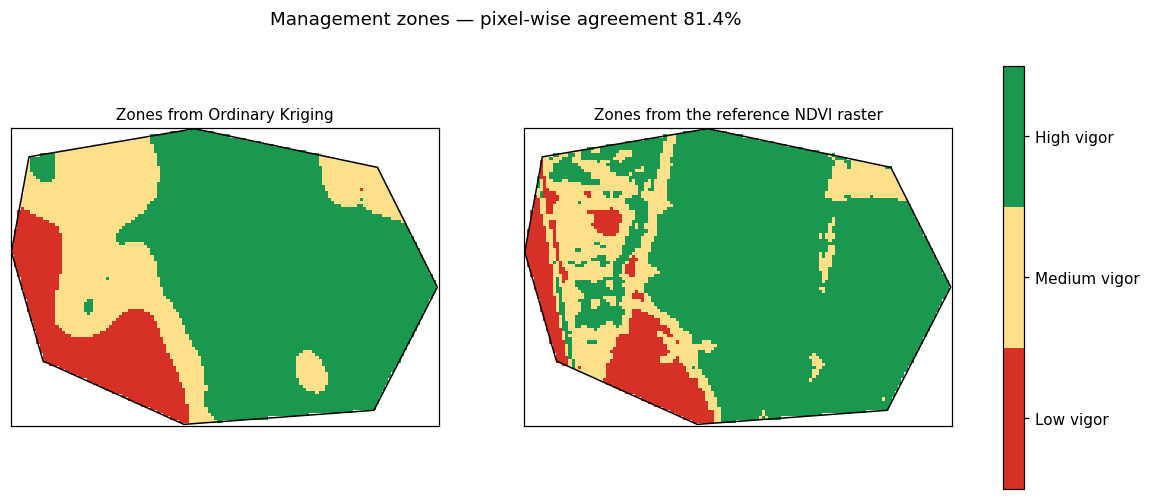


        Zone  Pixels  Area (ha)  Share (%)  Mean NDVI
   Low vigor    1320      13.20     13.454      0.494
Medium vigor    2500      25.00     25.482      0.718
  High vigor    5991      59.91     61.064      0.830


In [ ]:
from matplotlib.colors import ListedColormap

def zones_from(surface):
    flat = surface.ravel(); m = ~np.isnan(flat)
    km = KMeans(n_clusters=N_ZONES, random_state=MASTER_SEED, n_init=10)
    lab = km.fit_predict(flat[m].reshape(-1, 1))
    remap = {old: new for new, old in enumerate(np.argsort(km.cluster_centers_.ravel()))}
    out = np.full(flat.shape, np.nan); out[m] = [remap[l] for l in lab]
    return out.reshape(surface.shape)

zone_map = zones_from(surface_for_zoning)
zones_ref_map = zones_from(ndvi)
ZONE_AGREEMENT = float(np.mean(zone_map.ravel()[valid_flat] == zones_ref_map.ravel()[valid_flat]))

# How well does each method preserve the zoning decision?
zone_rows = [dict(Method=m,
                  **{'Zone agreement (%)': round(100 * float(np.mean(
                      zones_from(surfaces[m]).ravel()[valid_flat] ==
                      zones_ref_map.ravel()[valid_flat])), 1)})
             for m in METHOD_NAMES]
zone_agree_df = pd.DataFrame(zone_rows).sort_values('Zone agreement (%)', ascending=False)
print('Agreement with zones derived from the reference raster:\n')
print(zone_agree_df.to_string(index=False))
zone_agree_df.to_csv(f'{OUT_DIR}/T9b_zone_agreement_by_method.csv', index=False)

zone_names = ['Low vigor', 'Medium vigor', 'High vigor'][:N_ZONES]
zone_cmap = ListedColormap(['#d73027', '#fee08b', '#1a9850'][:N_ZONES])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, arr_, ttl in [(axes[0], zone_map, f'Zones from {zoning_method_name}'),
                      (axes[1], zones_ref_map, 'Zones from the reference NDVI raster')]:
    im = ax.imshow(arr_, cmap=zone_cmap, vmin=-0.5, vmax=N_ZONES - 0.5,
                   extent=plot_extent, origin='upper')
    field_utm.boundary.plot(ax=ax, color='black', linewidth=1)
    ax.set_title(ttl, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
cbar = plt.colorbar(im, ax=axes, ticks=range(N_ZONES), fraction=0.03)
cbar.ax.set_yticklabels(zone_names)
plt.suptitle(f'Management zones — pixel-wise agreement {100*ZONE_AGREEMENT:.1f}%', y=0.98)
plt.savefig(f'{OUT_DIR}/Fig8_management_zones.png', dpi=200, bbox_inches='tight')
plt.show()

px_ha = PIXEL_SIZE ** 2 / 1e4
zone_summary = pd.DataFrame({
    'Zone': zone_names,
    'Pixels': [int(np.nansum(zone_map == i)) for i in range(N_ZONES)],
    'Area (ha)': [float(np.nansum(zone_map == i) * px_ha) for i in range(N_ZONES)],
    'Share (%)': [float(100 * np.nansum(zone_map == i) / n_valid) for i in range(N_ZONES)],
    'Mean NDVI': [float(np.nanmean(surface_for_zoning[zone_map == i])) for i in range(N_ZONES)],
})
print('\n' + zone_summary.round(3).to_string(index=False))
zone_summary.to_csv(f'{OUT_DIR}/T9_management_zones.csv', index=False)

## §9. Georeferenced exports and interactive map

All rasters are written in **UTM 33N with the true affine transform** carried from
the clipped reference GeoTIFF — no bounding-box approximation anywhere. The
interactive map reprojects to WGS84 on the fly, purely for display.

In [ ]:
def write_gtiff(path, arr):
    with rasterio.open(path, 'w', driver='GTiff', height=n_rows, width=n_cols, count=1,
                       dtype='float32', crs=src_crs, transform=clip_transform,
                       nodata=SENTINEL) as dst:
        dst.write(np.where(np.isnan(arr), SENTINEL, arr).astype('float32'), 1)

def slug(s):
    return (s.lower().replace(' + ', '_').replace(' (', '_').replace(')', '')
            .replace(' ', '_').replace('é', 'e').replace('-', '_'))

for name, surf in surfaces.items():
    write_gtiff(f'{OUT_DIR}/reconstructed_{slug(name)}.tif', surf)
for name, s in sd_surfaces.items():
    write_gtiff(f'{OUT_DIR}/uncertainty_{slug(name)}.tif', s)
write_gtiff(f'{OUT_DIR}/management_zones.tif', zone_map)

E = clip_transform.c + xs_ref
N = clip_transform.f - ys_ref
samples_gdf = gpd.GeoDataFrame(
    dict(sample_id=np.arange(N_SAMPLES_MAIN), ndvi_measured=z_meas_ref, ndvi_true=z_true_ref),
    geometry=[Point(e, n) for e, n in zip(E, N)], crs=src_crs)
samples_gdf.to_file(f'{OUT_DIR}/simulated_samples.gpkg', driver='GPKG')
samples_gdf.drop(columns='geometry').to_csv(f'{OUT_DIR}/simulated_samples.csv', index=False)
field_utm.to_file(f'{OUT_DIR}/field_boundary.gpkg', driver='GPKG')

print('Exported:')
for f in sorted(os.listdir(OUT_DIR)):
    print('  ', f)

Exported:
   Fig1_study_area.png
   Fig2_reference_ndvi.png
   Fig3_variogram_models.png
   Fig4_method_distributions.png
   Fig5_uncertainty_calibration.png
   Fig6_density_sweep.png
   Fig7_reconstructions.png
   Fig7b_error_maps.png
   Fig7c_uncertainty_surfaces.png
   Fig8_management_zones.png
   T1_variogram_model_comparison.csv
   T2_repeated_split_runs.csv
   T3_heldout_repeated.csv
   T4_fullfield_repeated.csv
   T5_posthoc_tests.csv
   T5b_idw_vs_kriging.csv
   T5c_family_comparison.csv
   T5d_uncertainty_calibration.csv
   T6_density_sweep_runs.csv
   T7_density_summary.csv
   T8_reference_fullfield.csv
   T9_management_zones.csv
   T9b_zone_agreement_by_method.csv
   background_utm.tif
   field_boundary.geojson
   field_boundary.gpkg
   management_zones.tif
   ndvi_reference_utm_clipped.tif
   ndvi_reference_utm_raw.tif
   reconstructed_fourier_feature_mlp.tif
   reconstructed_gaussian_process_matern.tif
   reconstructed_gradient_boosting.tif
   reconstructed_idw_loocv_tuned

Interactive map saved -> output/field_interpolation_map.html



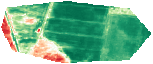
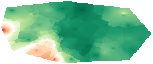
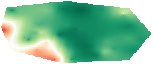
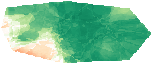
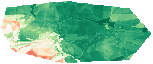
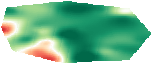
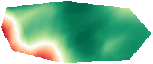
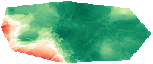
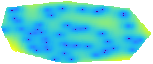
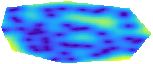
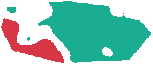

In [ ]:
import folium
from matplotlib.colors import Normalize
from matplotlib import colormaps

def reproject_to_4326(arr):
    src = np.where(np.isnan(arr), SENTINEL, arr).astype('float32')
    bounds = rasterio.transform.array_bounds(n_rows, n_cols, clip_transform)
    dst_tr, dw, dh = calculate_default_transform(src_crs, 'EPSG:4326', n_cols, n_rows, *bounds)
    dst = np.empty((dh, dw), dtype='float32')
    reproject(src, dst, src_transform=clip_transform, src_crs=src_crs,
              dst_transform=dst_tr, dst_crs='EPSG:4326',
              src_nodata=SENTINEL, dst_nodata=SENTINEL, resampling=Resampling.nearest)
    out = dst.astype(float); out[out == SENTINEL] = np.nan
    l, b, r, t = rasterio.transform.array_bounds(dh, dw, dst_tr)
    return out, [[b, l], [t, r]]

def to_rgba(arr, cmap_name=None, vmin=None, vmax=None, listed=None):
    if listed is not None:
        rgba = listed(Normalize(-0.5, len(listed.colors) - 0.5)(np.nan_to_num(arr, nan=0)))
    else:
        rgba = colormaps[cmap_name](Normalize(vmin, vmax)(arr))
    rgba[..., 3] = np.where(np.isnan(arr), 0.0, 0.78)
    return rgba

cen = field_gdf.geometry.iloc[0].centroid
m = folium.Map(location=[cen.y, cen.x], zoom_start=15, tiles=None)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri World Imagery', name='Satellite').add_to(m)

ndvi_ll, bnds = reproject_to_4326(ndvi)
folium.raster_layers.ImageOverlay(
    image=to_rgba(ndvi_ll, cmap_name='RdYlGn', vmin=0.2, vmax=0.9), bounds=bnds,
    name='Reference NDVI (Sentinel-2)', show=True).add_to(m)

for name in METHOD_NAMES:
    arr_ll, _ = reproject_to_4326(surfaces[name])
    folium.raster_layers.ImageOverlay(
        image=to_rgba(arr_ll, cmap_name='RdYlGn', vmin=0.2, vmax=0.9), bounds=bnds,
        name=f'Reconstruction — {name}', show=False).add_to(m)

for name, s in sd_surfaces.items():
    s_ll, _ = reproject_to_4326(s)
    folium.raster_layers.ImageOverlay(
        image=to_rgba(s_ll, cmap_name='viridis', vmin=float(np.nanmin(s)),
                      vmax=float(np.nanmax(s))), bounds=bnds,
        name=f'Uncertainty — {name}', show=False).add_to(m)

zone_ll, _ = reproject_to_4326(zone_map)
folium.raster_layers.ImageOverlay(image=to_rgba(zone_ll, listed=zone_cmap), bounds=bnds,
                                  name='Management zones', show=False).add_to(m)
folium.GeoJson(field_gdf.__geo_interface__, name='Field boundary',
               style_function=lambda _: dict(color='yellow', weight=3, fill=False)).add_to(m)

pts = samples_gdf.to_crs('EPSG:4326')
grp = folium.FeatureGroup(name='Simulated samples')
for geom, v in zip(pts.geometry, pts.ndvi_measured):
    folium.CircleMarker([geom.y, geom.x], radius=3, color='black', fill=True,
                        fill_opacity=0.9, popup=f'NDVI {v:.3f}').add_to(grp)
grp.add_to(m)
folium.LayerControl().add_to(m)
m.save(f'{OUT_DIR}/field_interpolation_map.html')
print(f'Interactive map saved -> {OUT_DIR}/field_interpolation_map.html')
m

## §10. Results summary for the manuscript

Every number the revised abstract and the 4–8 page paper need, printed and written
to `output/paper_results_summary.md`, so the text is filled from the run rather
than from memory.

In [ ]:
L = []
A = L.append
A('# Results summary (auto-generated)\n')
A(f'- Field: {FIELD_AREA_HA:.1f} ha parcel, Uckermark, Brandenburg; boundary provenance: {provenance}')
A(f'- Reference surface: Sentinel-2 NDVI, {PIXEL_SIZE:.0f} m, {DATE_START} to {DATE_END}'
  + (f', {N_SCENES} scenes' if N_SCENES else ''))
A(f'- Analysed pixels after polygon clipping: {n_valid:,} ({valid_area_ha:.1f} ha); '
  f'bounding-box extraction would have included {raw_area_ha:.1f} ha')
A(f'- NDVI over the parcel: mean {NDVI_STATS["mean"]:.3f}, SD {NDVI_STATS["std"]:.3f}, '
  f'range {NDVI_STATS["vmin"]:.3f}-{NDVI_STATS["vmax"]:.3f}')
A(f'- Methods compared: {len(METHODS)} '
  f'({", ".join(sorted(set(METHOD_FAMILY.values())))})')

A(f'\n## Variogram model selection ({VARIOGRAM_SEL_REPEATS} realisations)\n')
A(vario_summary.round(5).to_markdown())
A(f'\nSelected: **{VARIOGRAM_MODEL}**' +
  (f' (partial sill {PSILL:.4f}, range {VARIO_RANGE:.0f} m, nugget {NUGGET:.4f})'
   if np.isfinite(VARIO_RANGE) else ''))

A(f'\n## Repeated-split validation (n = {N_SAMPLES_MAIN}, {N_REPEATS} repetitions)\n')
A('### Held-out points (mean ± SD)\n')
A(held_out.to_markdown(index=False))
if FULL_FIELD_EACH_RUN:
    A('\n### Full field, all valid pixels (mean ± SD)\n')
    A(full_field.to_markdown(index=False))
A(f'\n### Friedman test\n')
A(f'chi² = {chi2:.2f}, df = {len(METHOD_NAMES)-1}, p = {p_friedman:.3e}')
A('\nMean ranks (1 = best):\n')
A(mean_ranks.round(2).to_markdown())
if len(post_df):
    A(f'\n### Post-hoc vs. {control} (Holm-corrected)\n')
    A(post_df.to_markdown(index=False))
A('\n### The pairwise claim from the submitted abstract\n')
A(pair.to_markdown(index=False))
A(f'\n**Verdict:** {OVERALL_VERDICT}')
A(f'\n**AI vs. geostatistics:** {AI_VERDICT}')
A(f'\nUncertainty calibration: {CALIB}')

A(f'\n## Sampling density sweep ({DENSITY_REPEATS} repetitions per density per method)\n')
A('Full-field RMSE by method and sample size:\n')
A(density_summary.pivot(index='n', columns='method', values='ff_RMSE_mean').round(4).to_markdown())
A(f'\n**Crossover:** {CROSSOVER}.')

A(f'\n## Reference reconstruction (single realisation, seed {MASTER_SEED})\n')
A(f'- IDW hyperparameters selected by LOOCV: power = {power_ref}, k = {k_ref} '
  f'(LOOCV RMSE {loocv_ref:.4f})')
A(ref_full.round(4).to_markdown(index=False))

A(f'\n## Management zones ({zoning_method_name} surface, K-means, k = {N_ZONES})\n')
A(zone_summary.round(3).to_markdown(index=False))
A(f'\nAgreement with reference-raster zones: {100*ZONE_AGREEMENT:.1f}% of pixels.\n')
A(zone_agree_df.to_markdown(index=False))

A('\n## Reproducibility\n')
A(f'- Master seed {MASTER_SEED}; boundary frozen at `{BOUNDARY_PATH}`; '
  f'reference raster cached at `{NDVI_TIF_CLIP}`')
A(f'- Config: N_SAMPLES_MAIN={N_SAMPLES_MAIN}, NOISE_STD={NOISE_STD}, '
  f'TEST_FRACTION={TEST_FRACTION}, N_REPEATS={N_REPEATS}, '
  f'DENSITIES={DENSITIES}, DENSITY_REPEATS={DENSITY_REPEATS}, '
  f'K_NEIGHBOURS={K_NEIGHBOURS}')

summary_md = '\n'.join(L)
with open(f'{OUT_DIR}/paper_results_summary.md', 'w') as f:
    f.write(summary_md)
print(summary_md)

# Results summary (auto-generated)

- Field: 98.1 ha parcel, Uckermark, Brandenburg; boundary provenance: digitised fallback polygon (Overpass unavailable)
- Reference surface: Sentinel-2 NDVI, 10 m, 2024-06-01 to 2024-07-15, 7 scenes
- Analysed pixels after polygon clipping: 9,811 (98.1 ha); bounding-box extraction would have included 131.5 ha
- NDVI over the parcel: mean 0.757, SD 0.144, range 0.235-0.896
- Methods compared: 7 (deep learning, deterministic, geostatistical, hybrid, machine learning)

## Variogram model selection (10 realisations)

| model       |   LOOCV_RMSE_mean |   LOOCV_RMSE_sd |   FitSSE_mean |   n_ok |
|:------------|------------------:|----------------:|--------------:|-------:|
| exponential |           0.10392 |         0.01171 |       0.00059 |     10 |
| spherical   |           0.10632 |         0.01259 |       0.00043 |     10 |
| linear      |           0.11113 |         0.01292 |       0.00024 |     10 |
| gaussian    |           0.74942 |         1.9878

### Remaining limitations to state in the paper

Worth writing into the Discussion rather than leaving for a reviewer to find:

1. **The samples are simulated, not measured.** Points are drawn from the
   Sentinel-2 raster with additive Gaussian noise, so they inherit the satellite's
   own spatial structure and error. Real soil probes or yield-monitor readings
   measure a different quantity with different, spatially correlated error —
   accuracy on real ground data will be lower than reported here. This is the
   limitation most likely to be challenged next.
2. **The learners are evaluated in the regime where they are weakest.** Forty
   training points is far below where neural networks are competitive. A fair
   reading of the AI comparison is "geostatistics is the right default at
   field-sampling densities", not "learning-based methods do not work for this
   problem" — the honest scope is one field at 0.2–2 samples ha⁻¹.
3. **No transfer learning across fields was attempted**, which is where deep
   learning would plausibly win: a network pre-trained on many fields could bring
   prior structure that kriging cannot. Testing that requires a multi-field
   dataset and is the natural next study.
4. **One field, one season.** Transferability across crops and phenological stages
   is untested.
5. **The reference is itself a product**, not truth: a cloud-masked median
   composite carries atmospheric-correction and compositing error.
6. **Ordinary kriging assumes second-order stationarity** over the parcel, only
   approximately true where management history creates sharp internal boundaries.
7. **Management zones have no agronomic validation** against yield or soil data,
   so the variable-rate step remains a proof of concept.